In [4]:
%pip install wfdb

Note: you may need to restart the kernel to use updated packages.


In [5]:
import wfdb

record = wfdb.rdrecord("100", pn_dir="mitdb")
annotations = wfdb.rdann("100", "atr", pn_dir="mitdb")

print("Signal shape:", record.p_signal.shape)
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)
print("Number of annotated beats:", len(annotations.sample))


Signal shape: (650000, 2)
Sampling frequency: 360
Channels: ['MLII', 'V5']
Number of annotated beats: 2274


### 1.2 Visualizing the Raw ECG Signal

An ECG signal represents the electrical activity of the heart over time. Before applying preprocessing techniques, we visualize a short segment of the original signal to examine its waveform and the locations of the expert annotations.

The recording is sampled at 360 Hz, meaning that 360 signal samples are collected per second. We will plot the first 10 seconds of the MLII channel.

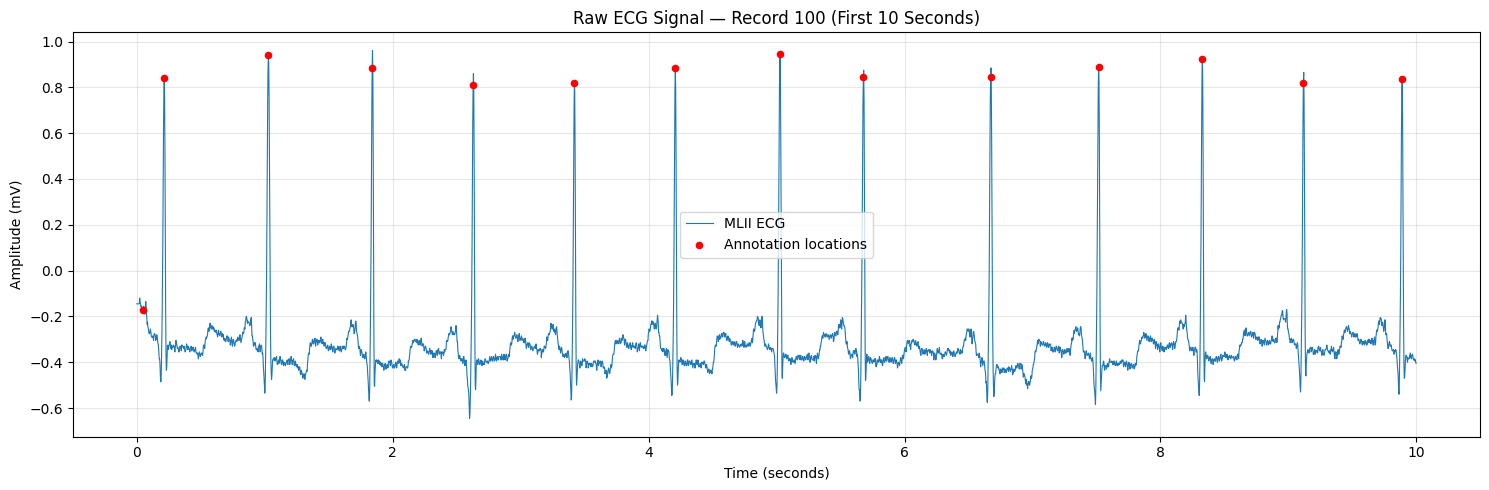

Duration plotted: 10 seconds
Annotations in this segment: 14


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Select the first 10 seconds of the MLII channel
duration = 10  # seconds
n_samples = duration * record.fs

ecg = record.p_signal[:n_samples, 0]
time = np.arange(n_samples) / record.fs

# Select annotations falling within these 10 seconds
mask = annotations.sample < n_samples
ann_samples = annotations.sample[mask]
ann_symbols = np.array(annotations.symbol)[mask]

# Plot the ECG signal
plt.figure(figsize=(15, 5))

plt.plot(time, ecg, linewidth=0.8, label="MLII ECG")

# Mark the annotation locations
plt.scatter(
    ann_samples / record.fs,
    ecg[ann_samples],
    color="red",
    s=20,
    label="Annotation locations",
    zorder=3
)

plt.title("Raw ECG Signal — Record 100 (First 10 Seconds)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Duration plotted:", duration, "seconds")
print("Annotations in this segment:", len(ann_samples))

### 1.3 Exploring Annotation Symbols

The MIT-BIH Arrhythmia Database provides expert annotations alongside ECG recordings. These annotations identify heartbeat types and may also include other events.

We will calculate the frequency of each annotation symbol in record 100. This will help us understand the available labels and identify potential class imbalance before preparing the classification dataset.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Count the occurrences of each annotation symbol
annotation_counts = (
    pd.Series(annotations.symbol, name="Annotation Symbol")
    .value_counts()
    .rename_axis("Annotation Symbol")
    .reset_index(name="Count")
)

# Display the complete frequency table
display(annotation_counts)

,Annotation Symbol,Count
0,N,2239
1,A,33
2,+,1
3,V,1


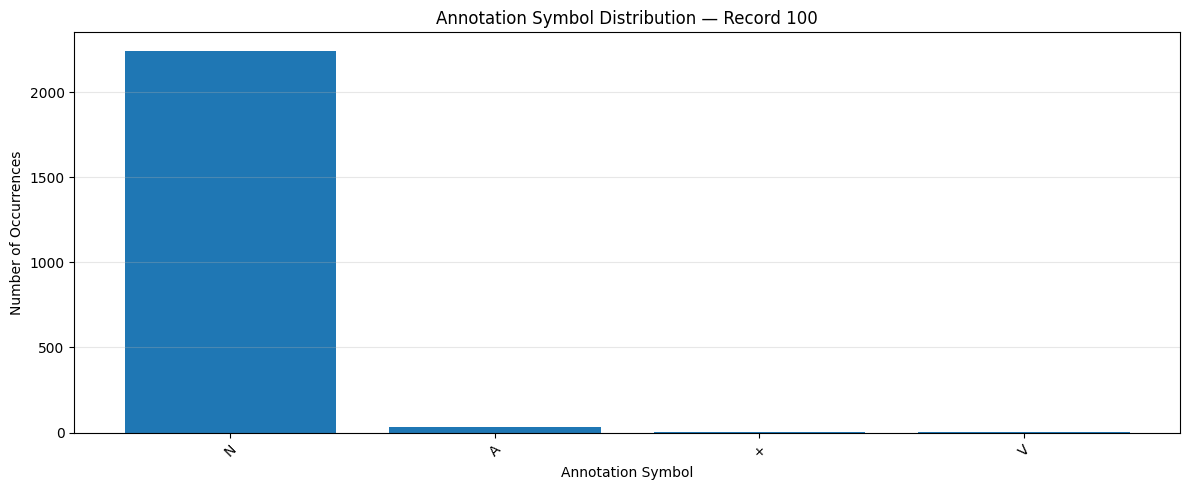

In [8]:
plt.figure(figsize=(12, 5))

plt.bar(
    annotation_counts["Annotation Symbol"].astype(str),
    annotation_counts["Count"]
)

plt.title("Annotation Symbol Distribution — Record 100")
plt.xlabel("Annotation Symbol")
plt.ylabel("Number of Occurrences")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 1.4 Exploring Annotation Symbols Across All Recordings

The previous analysis examined only record 100. To understand the dataset more comprehensively, we will retrieve the annotation files for all 48 MIT-BIH recordings and aggregate the frequency of each annotation symbol.

This analysis will help us identify common and rare symbols. Some annotations represent heartbeat types, while others represent rhythm changes or other events. We will distinguish these before defining the classification target.

In [9]:
from collections import Counter
import pandas as pd
import wfdb

# All 48 record IDs in the MIT-BIH Arrhythmia Database
record_names = [
    "100", "101", "102", "103", "104", "105",
    "106", "107", "108", "109", "111", "112",
    "113", "114", "115", "116", "117", "118",
    "119", "121", "122", "123", "124", "200",
    "201", "202", "203", "205", "207", "208",
    "209", "210", "212", "213", "214", "215",
    "217", "219", "220", "221", "222", "223",
    "228", "230", "231", "232", "233", "234"
]

symbol_counts = Counter()
record_annotation_counts = {}
failed_records = []

# Retrieve annotation files without loading all ECG signals
for record_name in record_names:
    try:
        ann = wfdb.rdann(
            record_name,
            "atr",
            pn_dir="mitdb/1.0.0"
        )

        symbol_counts.update(ann.symbol)
        record_annotation_counts[record_name] = len(ann.sample)

    except Exception as error:
        failed_records.append(record_name)
        print(f"Could not retrieve record {record_name}: {error}")

# Create a sorted frequency table
annotation_summary = pd.DataFrame(
    symbol_counts.items(),
    columns=["Annotation Symbol", "Count"]
).sort_values(
    "Count", ascending=False
).reset_index(drop=True)

print("Successfully retrieved recordings:",
      len(record_annotation_counts), "/", len(record_names))

print("Total annotation entries:", sum(symbol_counts.values()))

display(annotation_summary)

Successfully retrieved recordings: 48 / 48
Total annotation entries: 112647


,Annotation Symbol,Count
0,N,75052
1,L,8075
2,R,7259
3,V,7130
4,/,7028
5,A,2546
6,+,1291
7,f,982
8,F,803
9,~,616


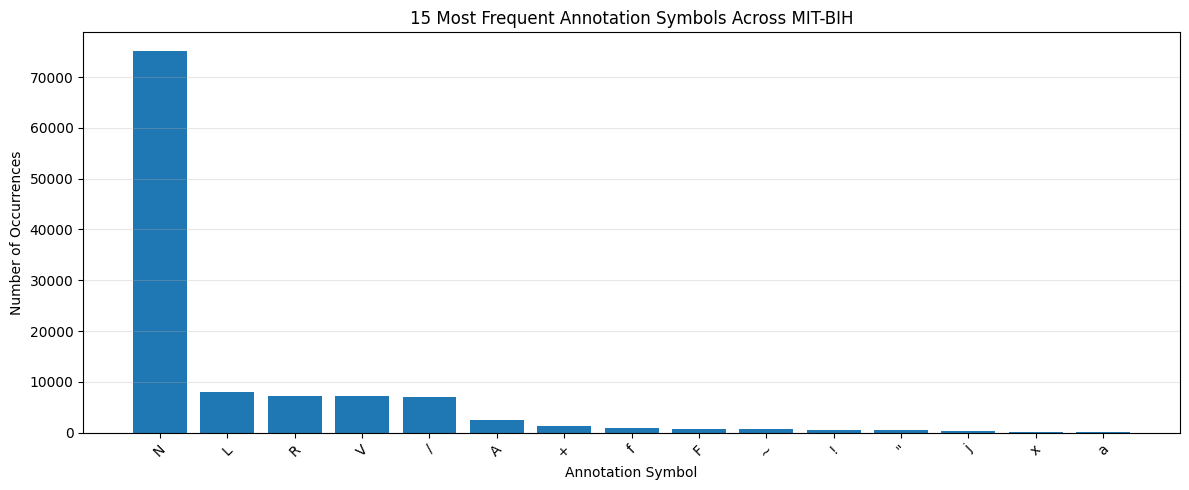

In [10]:
import matplotlib.pyplot as plt

top_symbols = annotation_summary.head(15)

plt.figure(figsize=(12, 5))

plt.bar(
    top_symbols["Annotation Symbol"].astype(str),
    top_symbols["Count"]
)

plt.title("15 Most Frequent Annotation Symbols Across MIT-BIH")
plt.xlabel("Annotation Symbol")
plt.ylabel("Number of Occurrences")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 1.5 Mapping Raw Annotations to AAMI Classes

The MIT-BIH database contains multiple original heartbeat annotation
symbols. To simplify classification and align the experiment with
established ECG research, we map these symbols into the five AAMI
superclasses: N, S, V, F, and Q.

Annotations that do not belong to the selected heartbeat classes
will not be treated as target labels.

We will examine the grouped class distribution before choosing
the final classification protocol.

In [11]:
from collections import Counter
import pandas as pd
import wfdb

# Map original MIT-BIH heartbeat symbols to AAMI classes
aami_mapping = {
    "N": "N",
    "L": "N",
    "R": "N",
    "e": "N",
    "j": "N",

    "A": "S",
    "a": "S",
    "J": "S",
    "S": "S",

    "V": "V",
    "E": "V",

    "F": "F",

    "/": "Q",
    "f": "Q",
    "Q": "Q"
}

class_order = ["N", "S", "V", "F", "Q"]

# The four paced recordings commonly excluded in this protocol
paced_records = {"102", "104", "107", "217"}

all_class_counts = Counter()
four_class_counts = Counter()
unmapped_symbols = Counter()
successful_records = []

for record_name in record_names:
    try:
        ann = wfdb.rdann(
            record_name,
            "atr",
            pn_dir="mitdb/1.0.0"
        )

        successful_records.append(record_name)

        for symbol in ann.symbol:
            if symbol not in aami_mapping:
                unmapped_symbols[symbol] += 1
                continue

            aami_class = aami_mapping[symbol]
            all_class_counts[aami_class] += 1

            # Count only the four selected classes in non-paced records
            if (
                record_name not in paced_records
                and aami_class in {"N", "S", "V", "F"}
            ):
                four_class_counts[aami_class] += 1

    except Exception as error:
        print(f"Could not process record {record_name}: {error}")

# Five-class distribution across all successfully processed records
five_class_summary = pd.DataFrame({
    "AAMI Class": class_order,
    "Description": [
        "Normal and related",
        "Supraventricular",
        "Ventricular",
        "Fusion",
        "Paced / unclassifiable"
    ],
    "Count": [all_class_counts[c] for c in class_order]
})

five_class_summary["Percentage"] = (
    100 * five_class_summary["Count"]
    / five_class_summary["Count"].sum()
).round(2)

print("Successfully processed recordings:",
      len(successful_records), "/", len(record_names))

print("\nFive-class distribution:")
display(five_class_summary)

# Candidate four-class distribution
four_class_summary = pd.DataFrame({
    "AAMI Class": ["N", "S", "V", "F"],
    "Description": [
        "Normal and related",
        "Supraventricular",
        "Ventricular",
        "Fusion"
    ],
    "Count": [four_class_counts[c] for c in ["N", "S", "V", "F"]]
})

four_class_summary["Percentage"] = (
    100 * four_class_summary["Count"]
    / four_class_summary["Count"].sum()
).round(2)

print("\nCandidate four-class distribution:")
display(four_class_summary)

print("\nMost frequent symbols outside our AAMI mapping:")
display(pd.DataFrame(
    unmapped_symbols.most_common(15),
    columns=["Unmapped Symbol", "Count"]
))

Successfully processed recordings: 48 / 48

Five-class distribution:


,AAMI Class,Description,Count,Percentage
0,N,Normal and related,90631,82.77
1,S,Supraventricular,2781,2.54
2,V,Ventricular,7236,6.61
3,F,Fusion,803,0.73
4,Q,Paced / unclassifiable,8043,7.35



Candidate four-class distribution:


,AAMI Class,Description,Count,Percentage
0,N,Normal and related,90125,89.48
1,S,Supraventricular,2781,2.76
2,V,Ventricular,7009,6.96
3,F,Fusion,803,0.80



Most frequent symbols outside our AAMI mapping:


,Unmapped Symbol,Count
0,+,1291
1,~,616
2,!,472
3,"""",437
4,x,193
5,|,132
6,[,6
7,],6


### 1.6 Finalizing the Classification Target

Based on the annotation analysis, we select four AAMI heartbeat
classes: N, S, V, and F.

The Q class is excluded from the initial classification task,
and the four paced recordings (102, 104, 107, and 217) are
excluded according to the selected protocol.

The resulting dataset exhibits substantial class imbalance.
Normal beats dominate the distribution, while fusion beats are
particularly rare. We will account for this during model training
and evaluate performance using class-sensitive metrics, including
macro-F1 and per-class recall.

## Experiment 2: ECG Signal Preprocessing

### 2.1 Comparing Raw and Filtered ECG Signals

ECG recordings may contain baseline drift and unwanted high-frequency
components. Filtering can reduce some of this interference while
preserving important waveform characteristics.

We apply a Butterworth band-pass filter between 0.5 Hz and 40 Hz
to the MLII channel of record 100 and compare the raw and filtered
signals over the same 10-second interval.

We will inspect the output before deciding whether to use these
filtering settings throughout the pipeline.

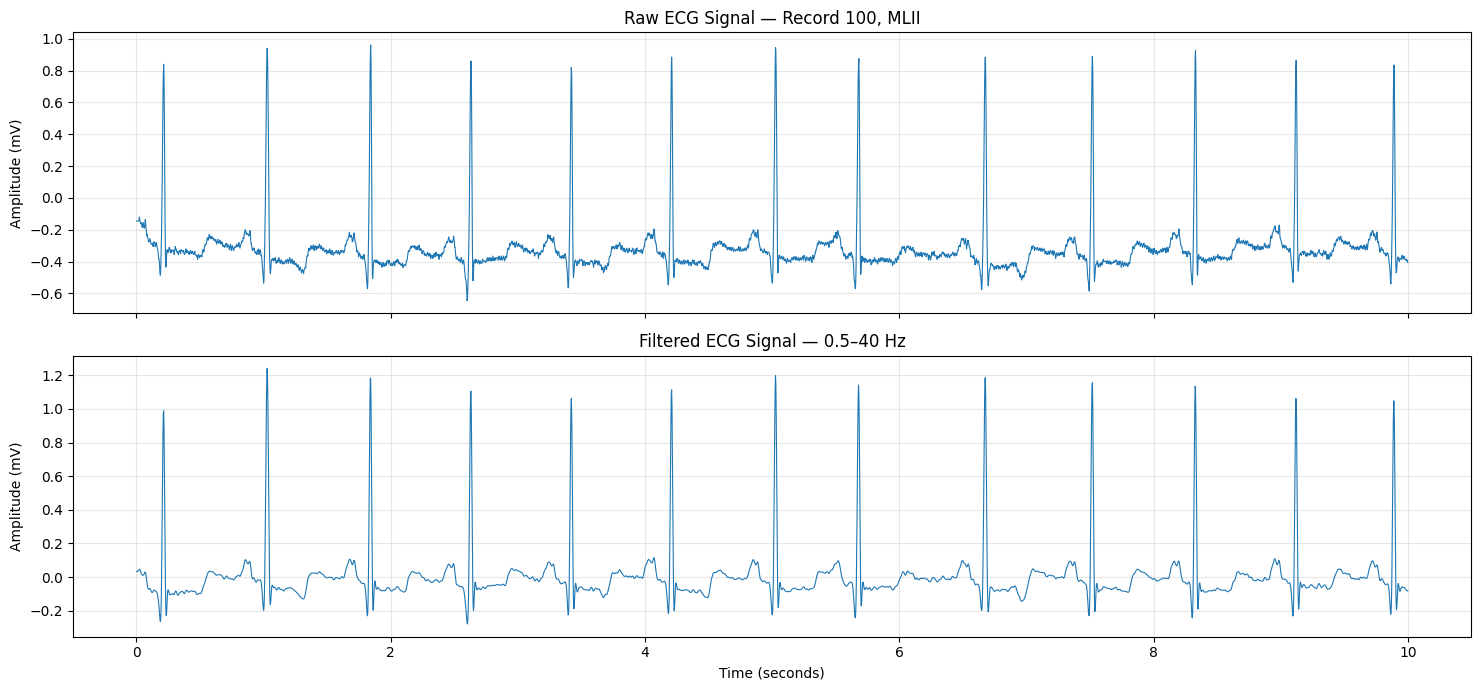

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Sampling frequency of the current recording
fs = record.fs

# Extract the complete MLII channel
raw_signal = record.p_signal[:, 0]

# Design a fourth-order Butterworth band-pass filter
sos = butter(
    4,
    [0.5, 40],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply zero-phase filtering
filtered_signal = sosfiltfilt(sos, raw_signal)

# Select the first 10 seconds for visualization
duration = 10
n_samples = int(duration * fs)

time = np.arange(n_samples) / fs
raw_segment = raw_signal[:n_samples]
filtered_segment = filtered_signal[:n_samples]

# Compare signals
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

axes[0].plot(time, raw_segment, linewidth=0.8)
axes[0].set_title("Raw ECG Signal — Record 100, MLII")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(alpha=0.3)

axes[1].plot(time, filtered_segment, linewidth=0.8)
axes[1].set_title("Filtered ECG Signal — 0.5–40 Hz")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude (mV)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

We can see that the main ECG waveform and sharp QRS peaks remain visible after filtering. The filtered signal also has a more centered baseline, which is consistent with removing some low-frequency drift.
Notice that the R-peak amplitudes differ slightly between the plots. Filtering changes the signal, so we shouldn't assume that smoother automatically means better. We'll assess the effect on classification later.

### 2.2 Verifying Heartbeat Annotation Alignment

The MIT-BIH database provides expert-annotated heartbeat locations.
We overlay these locations on the filtered ECG signal to verify
that they align with the corresponding waveform peaks.

Only annotations mapped to our four selected AAMI classes
(N, S, V, and F) are displayed as target heartbeats.

This visual check helps us detect indexing or alignment errors
before extracting individual heartbeat segments.

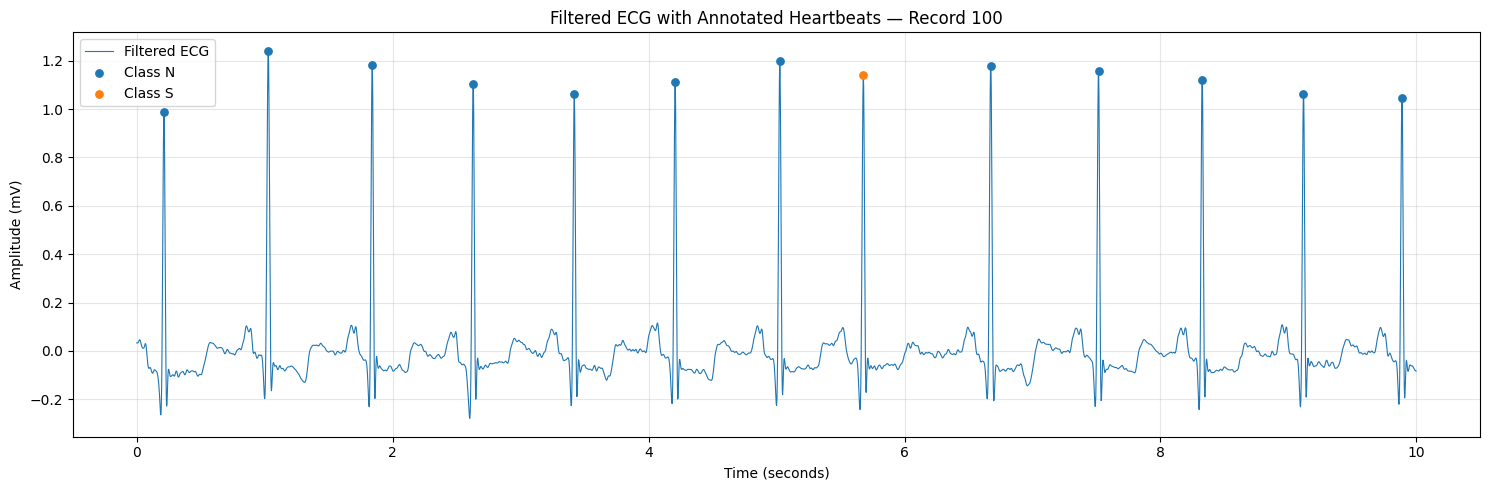

Target heartbeats marked: 13
Annotation mapping verified for the selected symbols.


In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Selected classification target
target_classes = {"N", "S", "V", "F"}

# Keep annotations that fall within the plotted 10-second segment
beat_samples = np.asarray(annotations.sample)
beat_symbols = np.asarray(annotations.symbol)

valid_indices = [
    i for i, (sample, symbol) in enumerate(
        zip(beat_samples, beat_symbols)
    )
    if sample < n_samples
    and symbol in aami_mapping
    and aami_mapping[symbol] in target_classes
]

# Plot the filtered ECG signal
plt.figure(figsize=(15, 5))
plt.plot(
    time,
    filtered_segment,
    linewidth=0.8,
    label="Filtered ECG"
)

# Mark heartbeat positions, grouped by AAMI class
for class_name in ["N", "S", "V", "F"]:
    class_samples = [
        beat_samples[i]
        for i in valid_indices
        if aami_mapping[beat_symbols[i]] == class_name
    ]

    if class_samples:
        plt.scatter(
            np.array(class_samples) / fs,
            filtered_signal[class_samples],
            s=28,
            label=f"Class {class_name}",
            zorder=3
        )

plt.title("Filtered ECG with Annotated Heartbeats — Record 100")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Target heartbeats marked:", len(valid_indices))
print("Annotation mapping verified for the selected symbols.")

### 3.1 Heartbeat Segmentation

The MIT-BIH database contains continuous ECG recordings. To prepare
the data for classical machine learning, we extract fixed-length
windows around expert-annotated heartbeat locations.

Each segment contains 0.2 seconds before and 0.4 seconds after
the annotated location. At a sampling frequency of 360 Hz, each
heartbeat contains 216 samples.

Only annotations belonging to our four selected classes (N, S, V,
and F) are retained. Segments that extend beyond the recording
boundaries are discarded because they cannot provide a complete
window.

We first validate this procedure on record 100 before processing
the remaining recordings.


In [14]:
import numpy as np
import pandas as pd

# Segmentation settings
fs = record.fs
pre_samples = int(0.2 * fs)
post_samples = int(0.4 * fs)
segment_length = pre_samples + post_samples

target_classes = {"N", "S", "V", "F"}

segments_100 = []
labels_100 = []
symbols_100 = []
positions_100 = []

# Extract segments from record 100
for sample, symbol in zip(annotations.sample, annotations.symbol):

    # Ignore symbols outside our selected heartbeat classes
    if symbol not in aami_mapping:
        continue

    label = aami_mapping[symbol]

    if label not in target_classes:
        continue

    start = int(sample) - pre_samples
    end = int(sample) + post_samples

    # Ensure that the entire heartbeat window is available
    if start < 0 or end > len(filtered_signal):
        continue

    segment = filtered_signal[start:end]

    # Ensure consistent input dimensions
    if len(segment) != segment_length:
        continue

    segments_100.append(segment.astype(np.float32))
    labels_100.append(label)
    symbols_100.append(symbol)
    positions_100.append(int(sample))

# Convert to arrays for analysis
X_100 = np.stack(segments_100)
y_100 = np.array(labels_100)

print("Heartbeat segments shape:", X_100.shape)
print("Number of segments:", len(X_100))
print("Samples per segment:", X_100.shape[1])
print("Segment duration:", segment_length / fs, "seconds")

print("\nClass distribution in record 100:")
display(
    pd.Series(y_100, name="AAMI Class")
    .value_counts()
    .reindex(["N", "S", "V", "F"], fill_value=0)
    .rename_axis("Class")
    .to_frame("Count")
)

Heartbeat segments shape: (2272, 216)
Number of segments: 2272
Samples per segment: 216
Segment duration: 0.6 seconds

Class distribution in record 100:


,Count
Class,
N,2238
S,33
V,1
F,0


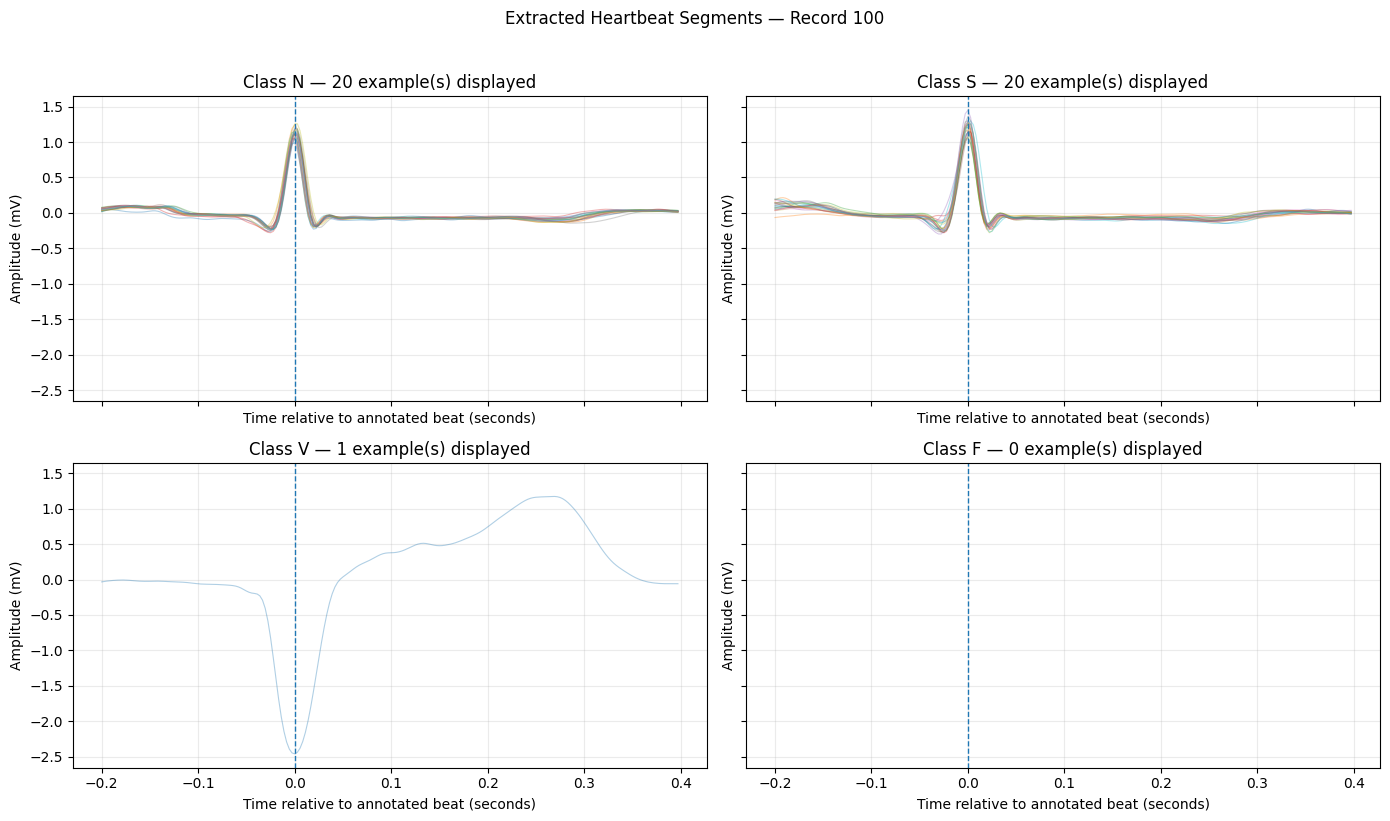

In [15]:
import matplotlib.pyplot as plt

relative_time = (
    np.arange(segment_length) - pre_samples
) / fs

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 8),
    sharex=True,
    sharey=True
)

for ax, class_name in zip(axes.flat, ["N", "S", "V", "F"]):

    indices = np.flatnonzero(y_100 == class_name)[:20]

    for idx in indices:
        ax.plot(relative_time, X_100[idx], alpha=0.35, linewidth=0.8)

    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_title(
        f"Class {class_name} — {len(indices)} example(s) displayed"
    )
    ax.set_xlabel("Time relative to annotated beat (seconds)")
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(alpha=0.25)

plt.suptitle("Extracted Heartbeat Segments — Record 100", y=1.02)
plt.tight_layout()
plt.show()

N and S waveforms overlap considerably. Their shapes can look similar, which helps explain why classification isn't always straightforward.



F has zero examples in record 100, while V has only one. That's expected for a single recording; we need to collect examples across the eligible recordings before training.

### 3.2 Extracting Heartbeats from the Eligible Recordings

We extend the segmentation procedure to the eligible MIT-BIH recordings.

For each recording, we:
1. Retrieve the ECG signal and its expert annotations.
2. Select one ECG channel, preferring MLII when available.
3. Apply the Butterworth band-pass filter established in Experiment 2.
4. Extract fixed-length 216-sample heartbeat windows.
5. Map each retained annotation to one of the four AAMI target classes.

We retain recording identifiers and heartbeat positions for traceability and patient-independent evaluation.

Record 201 and record 202 belong to the same subject. We preserve this relationship so these recordings cannot be placed in different data partitions later.

The extracted examples are not balanced artificially. The original class distribution is preserved for evaluation.


In [16]:
import numpy as np
import pandas as pd
import wfdb

from scipy.signal import butter, sosfiltfilt
from collections import Counter

# All MIT-BIH record identifiers
record_names = [
    "100", "101", "102", "103", "104", "105",
    "106", "107", "108", "109", "111", "112",
    "113", "114", "115", "116", "117", "118",
    "119", "121", "122", "123", "124", "200",
    "201", "202", "203", "205", "207", "208",
    "209", "210", "212", "213", "214", "215",
    "217", "219", "220", "221", "222", "223",
    "228", "230", "231", "232", "233", "234"
]

# Exclude these paced recordings in our selected protocol
paced_records = {"102", "104", "107", "217"}

# Original annotation symbol -> AAMI heartbeat class
aami_mapping = {
    "N": "N", "L": "N", "R": "N", "e": "N", "j": "N",
    "A": "S", "a": "S", "J": "S", "S": "S",
    "V": "V", "E": "V",
    "F": "F",
    "/": "Q", "f": "Q", "Q": "Q"
}

target_classes = {"N", "S", "V", "F"}

# Segmentation parameters
pre_samples = int(0.2 * 360)
post_samples = int(0.4 * 360)
segment_length = pre_samples + post_samples

# Storage for heartbeat examples and their metadata
all_segments = []
all_labels = []
all_symbols = []
all_record_ids = []
all_subject_groups = []
all_beat_positions = []
selected_channels = {}

failed_records = []

for record_name in record_names:

    if record_name in paced_records:
        continue

    try:
        # Retrieve the original ECG recording and annotations
        rec = wfdb.rdrecord(
            record_name,
            pn_dir="mitdb/1.0.0"
        )

        ann = wfdb.rdann(
            record_name,
            "atr",
            pn_dir="mitdb/1.0.0"
        )

        fs = rec.fs

        # Prefer MLII; otherwise use the first available channel.
        channel_names = [name.strip() for name in rec.sig_name]
        if "MLII" in channel_names:
            channel_idx = channel_names.index("MLII")
        else:
            channel_idx = 0

        selected_channels[record_name] = channel_names[channel_idx]

        # Filter this recording's selected channel
        signal = rec.p_signal[:, channel_idx].astype(np.float64)

        sos = butter(
            4,
            [0.5, 40],
            btype="bandpass",
            fs=fs,
            output="sos"
        )

        filtered = sosfiltfilt(sos, signal)

        # Calculate window sizes using the recording's sampling rate
        pre = int(0.2 * fs)
        post = int(0.4 * fs)

        group_id = (
            "subject_201_202"
            if record_name in {"201", "202"}
            else f"subject_{record_name}"
        )

        # Extract labelled heartbeat windows
        for sample, symbol in zip(ann.sample, ann.symbol):

            if symbol not in aami_mapping:
                continue

            label = aami_mapping[symbol]

            if label not in target_classes:
                continue

            start = int(sample) - pre
            end = int(sample) + post

            # Discard incomplete windows at recording boundaries
            if start < 0 or end > len(filtered):
                continue

            segment = filtered[start:end]

            if len(segment) != pre + post:
                continue

            all_segments.append(segment.astype(np.float32))
            all_labels.append(label)
            all_symbols.append(symbol)
            all_record_ids.append(record_name)
            all_subject_groups.append(group_id)
            all_beat_positions.append(int(sample))

        print(f"Processed record {record_name}")

    except Exception as error:
        failed_records.append(record_name)
        print(f"Failed to process record {record_name}: {error}")

# Convert the accumulated examples to arrays
X_all = np.stack(all_segments)
y_all = np.asarray(all_labels)

# Preserve identifiers and labels in a metadata table
metadata = pd.DataFrame({
    "record_id": all_record_ids,
    "subject_group": all_subject_groups,
    "beat_position": all_beat_positions,
    "original_symbol": all_symbols,
    "aami_class": all_labels
})

print("\n--- Extraction Summary ---")
print("Successfully processed recordings:",
      len(selected_channels), "/", len(record_names) - len(paced_records))
print("Failed recordings:", failed_records)
print("Heartbeat array shape:", X_all.shape)
print("Label array shape:", y_all.shape)
print("Samples per heartbeat:", X_all.shape[1])
print("Metadata rows:", len(metadata))

print("\nClass distribution:")
display(
    metadata["aami_class"]
    .value_counts()
    .reindex(["N", "S", "V", "F"], fill_value=0)
    .rename_axis("AAMI class")
    .to_frame("Count")
)

print("\nChannels selected:")
display(
    pd.Series(selected_channels, name="Selected channel")
    .value_counts()
    .rename_axis("Channel")
    .to_frame("Recordings")
)

Processed record 100
Processed record 101
Processed record 103
Processed record 105
Processed record 106
Processed record 108
Processed record 109
Processed record 111
Processed record 112
Processed record 113
Processed record 114
Processed record 115
Processed record 116
Processed record 117
Processed record 118
Processed record 119
Processed record 121
Processed record 122
Processed record 123
Processed record 124
Processed record 200
Processed record 201
Processed record 202
Processed record 203
Processed record 205
Processed record 207
Processed record 208
Processed record 209
Processed record 210
Processed record 212
Processed record 213
Processed record 214
Processed record 215
Processed record 219
Processed record 220
Processed record 221
Processed record 222
Processed record 223
Processed record 228
Processed record 230
Processed record 231
Processed record 232
Processed record 233
Processed record 234

--- Extraction Summary ---
Successfully processed recordings: 44 / 44
Faile

,Count
AAMI class,
N,90094
S,2781
V,7008
F,802



Channels selected:


,Recordings
Channel,
MLII,44


### 3.3 Validating the Extracted Dataset

Before proceeding to feature engineering, we verify that:
- The signal and label arrays contain the same number of examples.
- Every heartbeat has the expected number of samples.
- There are no non-finite values in the extracted signal data.
- The metadata contains the corresponding class labels and recording IDs.

These checks help identify data preparation errors before they affect model training and evaluation.

In [17]:
# Verify the dimensions and metadata alignment
assert len(X_all) == len(y_all) == len(metadata)
assert X_all.shape[1] == segment_length
assert metadata["aami_class"].isin(
    ["N", "S", "V", "F"]
).all()

print("All array lengths match:", len(X_all) == len(metadata))
print("All segments have the expected length:",
      X_all.shape[1] == segment_length)
print("All signal values are finite:",
      np.isfinite(X_all).all())
print("All labels belong to the selected classes:",
      set(y_all).issubset({"N", "S", "V", "F"}))
print("All metadata rows have recording IDs:",
      metadata["record_id"].notna().all())

print("\nFinal shape:", X_all.shape)

All array lengths match: True
All segments have the expected length: True
All signal values are finite: True
All labels belong to the selected classes: True
All metadata rows have recording IDs: True

Final shape: (100685, 216)


## Experiment 4: Feature Engineering

### 4.1 Extracting Waveform and Timing Features

Each heartbeat is represented by a 216-sample ECG segment.

We retain the waveform samples as morphology features and supplement
them with amplitude statistics, measurements around the QRS region,
and preceding and following RR intervals.

These features represent two kinds of information:
1. Waveform morphology: how the heartbeat looks.
2. Heartbeat timing: how the heartbeat relates to neighbouring beats.

Missing RR intervals at recording boundaries are retained as missing
values. They will be handled within the training pipeline to avoid
information leakage.

The expert annotations are used here to establish reference heartbeat
locations. Our eventual prediction pipeline must detect beats without
requiring expert annotations.

In [18]:
import numpy as np
import pandas as pd

# X_all: (100685, 216), created in Experiment 3

# The annotated beat is at sample index 72 in each segment:
# 0.2 seconds * 360 samples/second = 72 samples before the beat.
center = pre_samples

# Use a 0.1-second window centred on the annotated beat.
half_window = int(0.05 * 360)

qrs_start = center - half_window
qrs_end = center + half_window + 1

qrs_region = X_all[:, qrs_start:qrs_end]

# Features calculated across each complete heartbeat segment
waveform_summary = pd.DataFrame({
    "mean_amplitude": np.mean(X_all, axis=1),
    "std_amplitude": np.std(X_all, axis=1),
    "min_amplitude": np.min(X_all, axis=1),
    "max_amplitude": np.max(X_all, axis=1),
    "peak_to_peak": np.ptp(X_all, axis=1),
    "rms_amplitude": np.sqrt(np.mean(X_all ** 2, axis=1)),
    "qrs_peak_to_peak": np.ptp(qrs_region, axis=1),
    "qrs_rms": np.sqrt(np.mean(qrs_region ** 2, axis=1))
})

# Retain each sample of the heartbeat waveform as a feature.
waveform_samples = pd.DataFrame(
    X_all,
    columns=[f"waveform_{i:03d}" for i in range(X_all.shape[1])]
)

print("Waveform sample features:", waveform_samples.shape)
print("Summary features:", waveform_summary.shape)

display(waveform_summary.head())

Waveform sample features: (100685, 216)
Summary features: (100685, 8)


,mean_amplitude,std_amplitude,min_amplitude,max_amplitude,peak_to_peak,rms_amplitude,qrs_peak_to_peak,qrs_rms
0,-0.035194,0.168662,-0.264374,0.988435,1.252809,0.172295,1.252809,0.381765
1,0.006203,0.213702,-0.197444,1.240993,1.438437,0.213792,1.438437,0.492922
2,0.006389,0.192613,-0.230532,1.183630,1.414162,0.192719,1.414162,0.444143
3,0.003840,0.182991,-0.278717,1.105174,1.383891,0.183032,1.383891,0.426878
4,-0.005611,0.172782,-0.225754,1.061056,1.286810,0.172873,1.286810,0.391854


In [19]:
import wfdb
import numpy as np
import pandas as pd

# RR intervals are measured in seconds.
fs = 360.0

rr_previous = np.full(len(metadata), np.nan, dtype=np.float32)
rr_next = np.full(len(metadata), np.nan, dtype=np.float32)

rr_failed_records = []

# Process annotations one recording at a time.
for record_name, row_indices in metadata.groupby(
    "record_id", sort=False
).groups.items():

    try:
        ann = wfdb.rdann(
            str(record_name),
            "atr",
            pn_dir="mitdb/1.0.0"
        )

        # Include all mapped AAMI beat symbols, including Q.
        annotated_beats = np.asarray([
            sample
            for sample, symbol in zip(ann.sample, ann.symbol)
            if symbol in aami_mapping
        ], dtype=np.int64)

        # Retained examples from this recording
        row_indices = np.asarray(list(row_indices), dtype=int)
        selected_positions = metadata.loc[
            row_indices, "beat_position"
        ].to_numpy(dtype=np.int64)

        # Match the retained examples to positions in all annotated beats.
        locations = np.searchsorted(
            annotated_beats,
            selected_positions
        )

        for row_idx, sample, loc in zip(
            row_indices, selected_positions, locations
        ):
            # Confirm that this is an exact annotation match.
            if (
                loc >= len(annotated_beats)
                or annotated_beats[loc] != sample
            ):
                continue

            if loc > 0:
                rr_previous[row_idx] = (
                    sample - annotated_beats[loc - 1]
                ) / fs

            if loc + 1 < len(annotated_beats):
                rr_next[row_idx] = (
                    annotated_beats[loc + 1] - sample
                ) / fs

    except Exception as error:
        rr_failed_records.append(str(record_name))
        print(f"Could not calculate RR features for {record_name}: {error}")

print("Recordings with RR calculation errors:", rr_failed_records)
print("Missing preceding RR intervals:", np.isnan(rr_previous).sum())
print("Missing following RR intervals:", np.isnan(rr_next).sum())

rr_features = pd.DataFrame({
    "rr_previous_seconds": rr_previous,
    "rr_next_seconds": rr_next
})

display(rr_features.head())

Recordings with RR calculation errors: []
Missing preceding RR intervals: 36
Missing following RR intervals: 19


,rr_previous_seconds,rr_next_seconds
0,NaN,0.813889
1,0.813889,0.811111
2,0.811111,0.788889
3,0.788889,0.791667
4,0.791667,0.788889


In [20]:
# Combine waveform, summary, and RR-interval features
features_df = pd.concat(
    [
        waveform_samples.reset_index(drop=True),
        waveform_summary.reset_index(drop=True),
        rr_features.reset_index(drop=True)
    ],
    axis=1
)

# Keep input features, target labels, and metadata separate
X_features = features_df.to_numpy(dtype=np.float32)
y = metadata["aami_class"].to_numpy()

print("Feature matrix shape:", X_features.shape)
print("Target shape:", y.shape)
print("Total features per heartbeat:", X_features.shape[1])

print("\nMissing values per feature group:")
print("Waveform features:", features_df.iloc[:, :216].isna().sum().sum())
print("Summary features:", features_df.iloc[:, 216:224].isna().sum().sum())
print("RR-interval features:", features_df.iloc[:, 224:].isna().sum().to_dict())

# Validate the assembled data
assert len(X_features) == len(y) == len(metadata)
assert np.isfinite(X_features[:, :224]).all()
assert metadata["subject_group"].notna().all()

print("\nFeature matrix assembled successfully.")
print("Subject groups are available for leakage-safe splitting.")

Feature matrix shape: (100685, 226)
Target shape: (100685,)
Total features per heartbeat: 226

Missing values per feature group:
Waveform features: 0
Summary features: 0
RR-interval features: {'rr_previous_seconds': 36, 'rr_next_seconds': 19}

Feature matrix assembled successfully.
Subject groups are available for leakage-safe splitting.


## Experiment 5: Patient-Independent Data Splitting

### 5.1 Creating Training, Validation and Test Sets

We divide the extracted heartbeat dataset into training, validation,
and test partitions using subject groups.

StratifiedGroupKFold helps preserve class proportions while ensuring
that examples from the same subject do not appear in multiple
partitions. Records 201 and 202 are treated as one subject group.

The training set will be used to fit models and preprocessing
transformations, the validation set to compare candidate models
and select configurations, and the test set for final evaluation.

No imputation, feature scaling, or class balancing is fitted before
this split.

In [25]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

X = features_df.to_numpy(dtype=np.float32)
y = metadata["aami_class"].to_numpy()
groups = metadata["subject_group"].to_numpy()

# Deliberately assign the fusion-rich subject groups.
fixed_train_group = "subject_208"
fixed_val_group = "subject_223"
fixed_test_group = "subject_213"

fixed_groups = {
    fixed_train_group,
    fixed_val_group,
    fixed_test_group
}

# Indices of the three fixed subject groups
fixed_train_idx = np.flatnonzero(groups == fixed_train_group)
fixed_val_idx = np.flatnonzero(groups == fixed_val_group)
fixed_test_idx = np.flatnonzero(groups == fixed_test_group)

assert len(fixed_train_idx) > 0
assert len(fixed_val_idx) > 0
assert len(fixed_test_idx) > 0

# Split all remaining subject groups.
remaining_idx = np.flatnonzero(~np.isin(groups, list(fixed_groups)))

outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_rel, test_rest_rel = next(
    outer_splitter.split(
        X[remaining_idx],
        y[remaining_idx],
        groups=groups[remaining_idx]
    )
)

train_val_idx = remaining_idx[train_val_rel]
test_rest_idx = remaining_idx[test_rest_rel]

# Split the remaining training/validation pool.
inner_splitter = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=43
)

train_rel, val_rel = next(
    inner_splitter.split(
        X[train_val_idx],
        y[train_val_idx],
        groups=groups[train_val_idx]
    )
)

# Assemble final partitions, including the fixed groups.
train_idx = np.concatenate([
    train_val_idx[train_rel],
    fixed_train_idx
])

val_idx = np.concatenate([
    train_val_idx[val_rel],
    fixed_val_idx
])

test_idx = np.concatenate([
    test_rest_idx,
    fixed_test_idx
])

# Build the datasets.
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training examples:", len(train_idx))
print("Validation examples:", len(val_idx))
print("Test examples:", len(test_idx))

print("\nFixed subject assignments:")
print("Training: subject_208")
print("Validation: subject_223")
print("Testing: subject_213")

Training examples: 58295
Validation examples: 18869
Test examples: 23521

Fixed subject assignments:
Training: subject_208
Validation: subject_223
Testing: subject_213


In [26]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

assert "subject_208" in train_groups
assert "subject_223" in val_groups
assert "subject_213" in test_groups

class_order = ["N", "S", "V", "F"]

class_counts = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts().reindex(
        class_order, fill_value=0
    ),
    "Validation": pd.Series(y_val).value_counts().reindex(
        class_order, fill_value=0
    ),
    "Test": pd.Series(y_test).value_counts().reindex(
        class_order, fill_value=0
    )
})
class_counts.index.name = "AAMI Class"

class_percentages = (
    class_counts.div(class_counts.sum(axis=0), axis=1) * 100
).round(2)

print("Unique subject groups:")
print("Train:", len(train_groups))
print("Validation:", len(val_groups))
print("Test:", len(test_groups))

print("\nHeartbeat counts:")
display(class_counts)

print("Class percentages within each partition:")
display(class_percentages)

print("\nNo subject overlap:", (
    train_groups.isdisjoint(val_groups)
    and train_groups.isdisjoint(test_groups)
    and val_groups.isdisjoint(test_groups)
))

Unique subject groups:
Train: 25
Validation: 8
Test: 10

Heartbeat counts:


,Train,Validation,Test
AAMI Class,,,
N,53752,16762,19580
S,1997,192,592
V,2144,1890,2974
F,402,25,375


Class percentages within each partition:


,Train,Validation,Test
AAMI Class,,,
N,92.21,88.83,83.24
S,3.43,1.02,2.52
V,3.68,10.02,12.64
F,0.69,0.13,1.59



No subject overlap: True


In [27]:
class_order = ["N", "S", "V", "F"]

class_counts = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts().reindex(
        class_order, fill_value=0
    ),
    "Validation": pd.Series(y_val).value_counts().reindex(
        class_order, fill_value=0
    ),
    "Test": pd.Series(y_test).value_counts().reindex(
        class_order, fill_value=0
    )
})

display(class_counts)

,Train,Validation,Test
N,53752,16762,19580
S,1997,192,592
V,2144,1890,2974
F,402,25,375


In [28]:
# Inspect which recordings contain fusion beats
fusion_by_record = (
    metadata[metadata["aami_class"] == "F"]
    .groupby(["subject_group", "record_id"])
    .size()
    .reset_index(name="Fusion Count")
    .sort_values("Fusion Count", ascending=False)
)

print("Recordings containing fusion beats:")
display(fusion_by_record)

print("\nNumber of subject groups containing fusion beats:",
      fusion_by_record["subject_group"].nunique())

Recordings containing fusion beats:


,subject_group,record_id,Fusion Count
9,subject_208,208,372
11,subject_213,213,362
15,subject_223,223,14
16,subject_233,233,11
8,subject_205,205,11
10,subject_210,210,10
3,subject_124,124,5
2,subject_114,114,4
0,subject_108,108,2
1,subject_109,109,2



Number of subject groups containing fusion beats: 16


### 5.2 Refining the Split for Rare Heartbeat Classes

The initial subject-independent split contained very few fusion beats
in the test set. Inspection showed that most fusion examples occur in
records 208 and 213, while record 223 contains additional examples.

We assign record 208 to training, record 223 to validation, and record
213 to testing. The remaining subject groups are distributed using
StratifiedGroupKFold.

This targeted split ensures that fusion beats are represented in all
three partitions without placing recordings from the same subject
in different partitions. We will report the actual class distributions
and acknowledge the limited number of fusion-rich subjects.

## Experiment 6: Baseline Model Training

### 6.1 Building Baseline Classification Pipelines

We train three classical machine-learning models to classify
ECG heartbeats into the N, S, V, and F categories.

The models are:
1. Logistic Regression
2. Linear Support Vector Machine (SVM)
3. Random Forest

Missing RR-interval features are imputed using training-set medians.
Feature scaling is applied to Logistic Regression and Linear SVM,
but not to Random Forest.

All transformations are fitted exclusively on the training data.
The validation set is used to compare baseline performance.
The held-out test set remains untouched until final evaluation.

No class weighting or ensemble learning is introduced in this
experiment; these will be investigated separately.

In [29]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Use consistent class ordering for evaluation
class_order = ["N", "S", "V", "F"]

# Define the baseline pipelines
baseline_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            solver="lbfgs",
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LinearSVC(
            C=1.0,
            dual="auto",
            max_iter=5000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Store validation predictions and evaluation results
baseline_predictions = {}
baseline_results = []

for name, pipeline in baseline_models.items():

    print(f"\nTraining {name}...")
    pipeline.fit(X_train, y_train)

    # Evaluate using validation data only
    y_pred = pipeline.predict(X_val)
    baseline_predictions[name] = y_pred

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
        "Macro-F1": f1_score(
            y_val,
            y_pred,
            labels=class_order,
            average="macro",
            zero_division=0
        )
    }

    baseline_results.append(result)

    print(f"\n{name} — Validation classification report:")
    print(classification_report(
        y_val,
        y_pred,
        labels=class_order,
        target_names=class_order,
        zero_division=0
    ))

# Summarize and rank models by macro-F1
baseline_results_df = pd.DataFrame(baseline_results)
baseline_results_df = baseline_results_df.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

print("\nBaseline Model Comparison — Validation Set")
display(baseline_results_df.round(4))


Training Logistic Regression...

Logistic Regression — Validation classification report:
              precision    recall  f1-score   support

           N       0.97      0.98      0.98     16762
           S       0.04      0.12      0.07       192
           V       0.93      0.58      0.71      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.93     18869
   macro avg       0.49      0.42      0.44     18869
weighted avg       0.96      0.93      0.94     18869


Training Linear SVM...

Linear SVM — Validation classification report:
              precision    recall  f1-score   support

           N       0.95      1.00      0.98     16762
           S       0.04      0.08      0.05       192
           V       0.98      0.48      0.65      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.93     18869
   macro avg       0.49      0.39      0.42     18869
weighted avg       0.95

,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Logistic Regression,0.9333,0.4215,0.4390
1,Linear SVM,0.9348,0.3906,0.4183
2,Random Forest,0.8625,0.3967,0.3619


Model	Accuracy	Macro-F1	Key observation
Logistic Regression	93.33%	0.4390	Best overall baseline by macro-F1
Linear SVM	93.48%	0.4183	Slightly higher accuracy, lower macro-F1
Random Forest	86.25%	0.3619	Better V-beat recall, but misses S and F completely
The key issue is class imbalance. Normal beats account for most validation examples, so a model can obtain high accuracy without detecting rare heartbeat types well.

### 6.2 Hyperparameter Tuning

We tune the baseline models to identify settings that improve
classification performance.

Logistic Regression and Linear SVM are tuned over their
regularization strength, C. Random Forest is tuned over tree
depth, number of trees, and minimum leaf size.

We use three-fold StratifiedGroupKFold cross-validation within
the training set, keeping each subject group within one fold.

Macro-F1 is the selection metric because the heartbeat classes
are imbalanced. The validation set is used for subsequent
comparison, while the test set remains untouched.

In [36]:
from sklearn.metrics import f1_score

CLASS_ORDER = ["N", "S", "V", "F"]

def macro_f1_cv_scorer(estimator, X_fold, y_true):
    """Calculate macro-F1 for our four heartbeat classes."""
    y_pred = estimator.predict(X_fold)

    return f1_score(
        y_true,
        y_pred,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

print("Custom multiclass macro-F1 scorer is ready.")

Custom multiclass macro-F1 scorer is ready.


In [39]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score
from scipy.stats import randint

# Fixed class order ensures every class is included in macro-F1.
macro_f1_scorer = make_scorer(
    f1_score,
    labels=["N", "S", "V", "F"],
    average="macro",
    zero_division=0
)

# Group-aware cross-validation using training subjects only.
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

train_groups_cv = groups[train_idx]

# Search spaces: keep this experiment compact.
search_spaces = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0]
    },
    "Linear SVM": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 20, 40],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__max_features": ["sqrt", 0.5]
    }
}

tuned_models = {}
tuning_results = []

for name, pipeline in baseline_models.items():
    print(f"\nTuning {name}...")

    if name == "Random Forest":
        search = RandomizedSearchCV(
            estimator=clone(pipeline),
            param_distributions=search_spaces[name],
            n_iter=6,
            scoring=macro_f1_cv_scorer,
            cv=cv,
            refit=True,
            random_state=42,
            n_jobs=1,
            verbose=2
        )
    else:
        search = GridSearchCV(
            estimator=clone(pipeline),
            param_grid=search_spaces[name],
            scoring=macro_f1_cv_scorer,
            cv=cv,
            refit=True,
            n_jobs=-1,
            verbose=2
        )

    search.fit(
        X_train,
        y_train,
        groups=train_groups_cv
    )

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV Macro-F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV Macro-F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values("Best CV Macro-F1", ascending=False)
    .reset_index(drop=True)
)

print("\nHyperparameter Search Results")
display(tuning_results_df)


Tuning Logistic Regression...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best CV Macro-F1: 0.4076
Best parameters: {'classifier__C': 0.01}

Tuning Linear SVM...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best CV Macro-F1: 0.4282
Best parameters: {'classifier__C': 0.01}

Tuning Random Forest...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END .................................classifier__C=0.01; total time=   9.2s
[CV] END ..................................classifier__C=0.1; total time=   9.5s
[CV] END .................................classifier__C=10.0; total time=  20.1s
[CV] END .................................classifier__C=0.01; total time=  22.0s
[CV] END ..................................classifier__C=1.0; total time=  37.4s
[CV] END ..................................classifier__C=0.1; total time=  11.2s
[CV] END ..................................classifier__C=1.0; total time=  15.4s
[CV] END .................................c

KeyboardInterrupt: 

In [40]:
import time
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import f1_score

# Ensure correct multiclass scoring
CLASS_ORDER = ["N", "S", "V", "F"]

def macro_f1_cv_scorer(estimator, X_fold, y_true):
    y_pred = estimator.predict(X_fold)
    return f1_score(
        y_true,
        y_pred,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )

# Keep subject groups together during cross-validation
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

train_groups_cv = groups[train_idx]

# Four reasonably bounded Random Forest configurations
rf_param_grid = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [15, 25],
    "classifier__min_samples_leaf": [5],
    "classifier__max_features": ["sqrt"]
}

print("Starting Random Forest tuning...")
print("4 configurations × 3 folds = 12 cross-validation fits.")
print("Progress will appear below.\n", flush=True)

rf_search = GridSearchCV(
    estimator=clone(baseline_models["Random Forest"]),
    param_grid=rf_param_grid,
    scoring=macro_f1_cv_scorer,
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

start_time = time.perf_counter()

rf_search.fit(
    X_train,
    y_train,
    groups=train_groups_cv
)

elapsed_minutes = (time.perf_counter() - start_time) / 60

# Preserve the other tuned models and update Random Forest only
tuned_models["Random Forest"] = rf_search.best_estimator_

tuning_results = [
    result for result in tuning_results
    if result["Model"] != "Random Forest"
]

tuning_results.append({
    "Model": "Random Forest",
    "Best CV Macro-F1": rf_search.best_score_,
    "Best Parameters": rf_search.best_params_,
    "Elapsed Time (min)": round(elapsed_minutes, 2)
})

print("\nRandom Forest tuning completed.")
print(f"Elapsed time: {elapsed_minutes:.2f} minutes")
print(f"Best CV Macro-F1: {rf_search.best_score_:.4f}")
print("Best parameters:", rf_search.best_params_)

display(
    pd.DataFrame(tuning_results)
    .sort_values("Best CV Macro-F1", ascending=False)
    .reset_index(drop=True)
)

Starting Random Forest tuning...
4 configurations × 3 folds = 12 cross-validation fits.
Progress will appear below.

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=50; total time=  24.5s
[CV] END classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=50; total time=  21.0s
[CV] END classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=50; total time=  21.6s
[CV] END classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time=  47.0s
[CV] END classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__n_estimators=100; total time=  40.1s
[CV] END classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_l

,Model,Best CV Macro-F1,Best Parameters,Elapsed Time (min)
0,Linear SVM,0.428230,{'classifier__C': 0.01},NaN
1,Logistic Regression,0.407626,{'classifier__C': 0.01},NaN
2,Random Forest,0.345269,"{'classifier__max_depth': 15, 'classifier__max...",8.32


### 6.3 Evaluating Tuned Models

We evaluate the best configuration of each model on the validation
set using accuracy, balanced accuracy, macro-F1, and class-wise
precision and recall.

The models are evaluated on the same observations to ensure a fair
comparison. The test set remains untouched until final evaluation.

Particular attention is given to the S, V, and F classes because
their lower frequency can make overall accuracy misleading.

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

class_order = ["N", "S", "V", "F"]

tuned_validation_results = []
tuned_val_predictions = {}

for name, model in tuned_models.items():

    print(f"\nEvaluating {name}...", flush=True)

    # Predict on the same validation set
    y_pred = model.predict(X_val)
    tuned_val_predictions[name] = y_pred

    tuned_validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
        "Macro-F1": f1_score(
            y_val,
            y_pred,
            labels=class_order,
            average="macro",
            zero_division=0
        )
    })

    print(f"\n{name} — Validation Report")
    print(classification_report(
        y_val,
        y_pred,
        labels=class_order,
        target_names=class_order,
        zero_division=0
    ))

# Compare models by macro-F1
tuned_validation_df = (
    pd.DataFrame(tuned_validation_results)
    .sort_values("Macro-F1", ascending=False)
    .reset_index(drop=True)
)

print("\nTuned Model Comparison — Validation Set")
display(tuned_validation_df.round(4))


Evaluating Logistic Regression...

Logistic Regression — Validation Report
              precision    recall  f1-score   support

           N       0.96      1.00      0.98     16762
           S       0.06      0.09      0.07       192
           V       0.98      0.59      0.74      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.94     18869
   macro avg       0.50      0.42      0.45     18869
weighted avg       0.95      0.94      0.94     18869


Evaluating Linear SVM...

Linear SVM — Validation Report
              precision    recall  f1-score   support

           N       0.95      1.00      0.98     16762
           S       0.03      0.07      0.05       192
           V       0.98      0.46      0.63      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.93     18869
   macro avg       0.49      0.38      0.41     18869
weighted avg       0.95      0.93      0.93     188

,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Random Forest,0.9553,0.4287,0.4590
1,Logistic Regression,0.9448,0.4195,0.4470
2,Linear SVM,0.9337,0.3836,0.4125


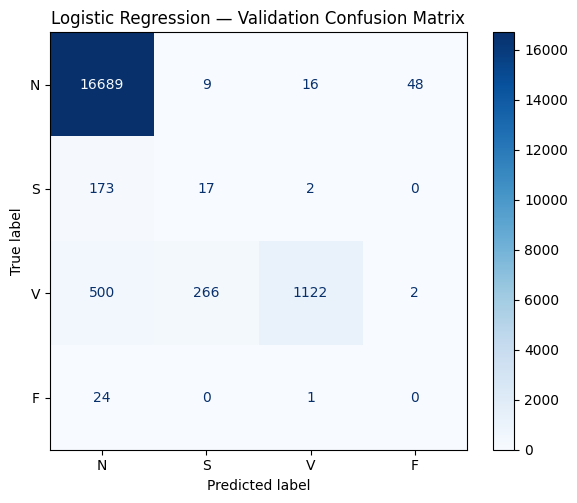

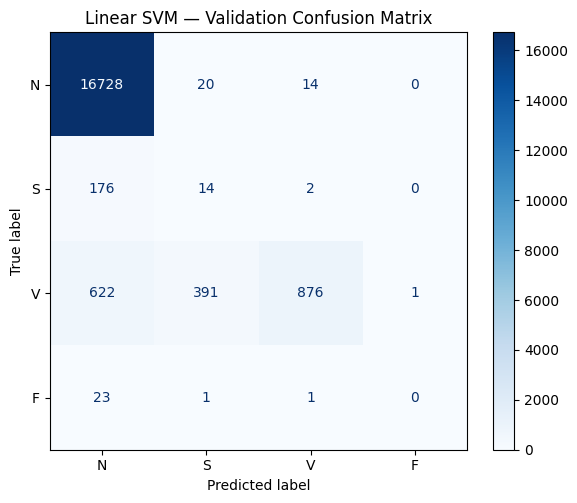

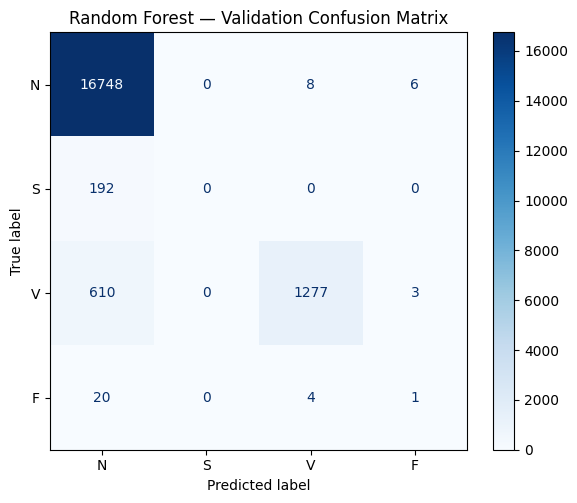

In [42]:
for name, y_pred in tuned_val_predictions.items():

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        labels=class_order,
        display_labels=class_order,
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(f"{name} — Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

## Experiment 7: Handling Class Imbalance

### 7.1 Evaluating Class-Weighted Models

The baseline experiments showed high overall accuracy but weak
detection of underrepresented heartbeat classes.

We address this by training class-weighted versions of the three
tuned models. The balanced class weights increase the penalty
associated with errors on less frequent classes.

We compare the class-weighted models against the tuned baseline
models using the same validation set.

We evaluate accuracy, balanced accuracy, macro-F1, and the
precision and recall of each heartbeat class.

The test set remains untouched.

In [43]:
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

CLASS_ORDER = ["N", "S", "V", "F"]

class_weighted_models = {}
class_weighted_results = {}
class_weighted_predictions = {}

for name, tuned_model in tuned_models.items():

    print(f"\n{'=' * 55}")
    print(f"Training class-weighted {name}...")
    print("=" * 55, flush=True)

    # Copy the tuned pipeline without changing the original.
    weighted_model = clone(tuned_model)

    # Give rare classes greater influence during training.
    weighted_model.set_params(
        classifier__class_weight="balanced"
    )

    weighted_model.fit(X_train, y_train)

    # Evaluate on exactly the same validation examples.
    y_pred = weighted_model.predict(X_val)

    class_weighted_models[name] = weighted_model
    class_weighted_predictions[name] = y_pred

    metrics = {
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
        "Macro-F1": f1_score(
            y_val,
            y_pred,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )
    }

    class_weighted_results[name] = metrics

    print(f"\n{name} — Class-Weighted Validation Report")
    print(classification_report(
        y_val,
        y_pred,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        zero_division=0
    ))

# Compile results for comparison.
weighted_df = pd.DataFrame([
    {"Model": name, **metrics}
    for name, metrics in class_weighted_results.items()
])

weighted_df = weighted_df.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

print("\nClass-Weighted Model Results")
display(weighted_df.round(4))


Training class-weighted Logistic Regression...

Logistic Regression — Class-Weighted Validation Report
              precision    recall  f1-score   support

           N       0.99      0.80      0.89     16762
           S       0.09      0.83      0.16       192
           V       0.83      0.76      0.79      1890
           F       0.00      0.24      0.01        25

    accuracy                           0.80     18869
   macro avg       0.48      0.66      0.46     18869
weighted avg       0.97      0.80      0.87     18869


Training class-weighted Linear SVM...

Linear SVM — Class-Weighted Validation Report
              precision    recall  f1-score   support

           N       0.97      0.98      0.98     16762
           S       0.12      0.54      0.19       192
           V       0.97      0.54      0.69      1890
           F       0.08      0.16      0.10        25

    accuracy                           0.93     18869
   macro avg       0.53      0.55      0.49     1

,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Linear SVM,0.9312,0.5544,0.4914
1,Logistic Regression,0.7997,0.6589,0.4617
2,Random Forest,0.9627,0.4396,0.4608


In [44]:
# The earlier tuned model results are stored in tuned_validation_df.
baseline_comparison = tuned_validation_df[
    ["Model", "Accuracy", "Balanced Accuracy", "Macro-F1"]
].copy()

baseline_comparison["Training Strategy"] = "Tuned baseline"

weighted_comparison = weighted_df[
    ["Model", "Accuracy", "Balanced Accuracy", "Macro-F1"]
].copy()

weighted_comparison["Training Strategy"] = "Class-weighted"

comparison_df = pd.concat(
    [baseline_comparison, weighted_comparison],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Model", "Training Strategy",
     "Accuracy", "Balanced Accuracy", "Macro-F1"]
].sort_values(
    ["Model", "Training Strategy"]
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Training Strategy,Accuracy,Balanced Accuracy,Macro-F1
0,Linear SVM,Class-weighted,0.9312,0.5544,0.4914
1,Linear SVM,Tuned baseline,0.9337,0.3836,0.4125
2,Logistic Regression,Class-weighted,0.7997,0.6589,0.4617
3,Logistic Regression,Tuned baseline,0.9448,0.4195,0.4470
4,Random Forest,Class-weighted,0.9627,0.4396,0.4608
5,Random Forest,Tuned baseline,0.9553,0.4287,0.4590


### 7.2 Analysing Class-Weighted Model Predictions

We compare the confusion matrices and class-wise precision, recall,
and F1-scores of the tuned baseline and class-weighted models.

The objective is to determine which classes benefit from class
weighting and whether the models make complementary errors.

These results will guide our decision about which models, if any,
should be combined in the ensemble.


Logistic Regression — Baseline
              precision    recall  f1-score   support

           N       0.96      1.00      0.98     16762
           S       0.06      0.09      0.07       192
           V       0.98      0.59      0.74      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.94     18869
   macro avg       0.50      0.42      0.45     18869
weighted avg       0.95      0.94      0.94     18869



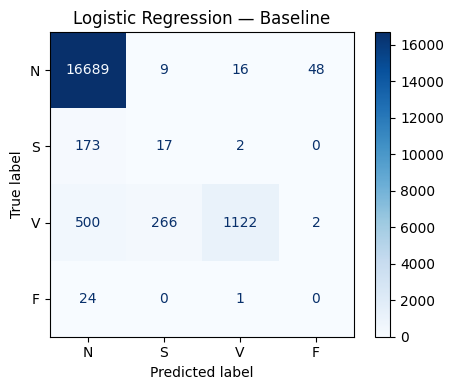


Logistic Regression — Class-weighted
              precision    recall  f1-score   support

           N       0.99      0.80      0.89     16762
           S       0.09      0.83      0.16       192
           V       0.83      0.76      0.79      1890
           F       0.00      0.24      0.01        25

    accuracy                           0.80     18869
   macro avg       0.48      0.66      0.46     18869
weighted avg       0.97      0.80      0.87     18869



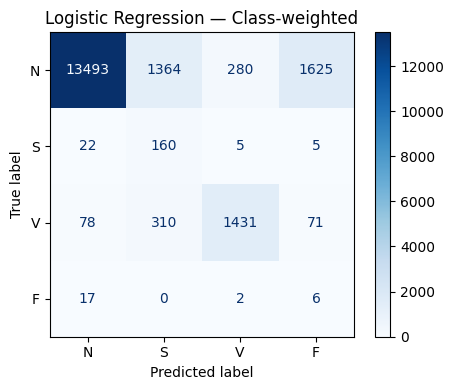


Linear SVM — Baseline
              precision    recall  f1-score   support

           N       0.95      1.00      0.98     16762
           S       0.03      0.07      0.05       192
           V       0.98      0.46      0.63      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.93     18869
   macro avg       0.49      0.38      0.41     18869
weighted avg       0.95      0.93      0.93     18869



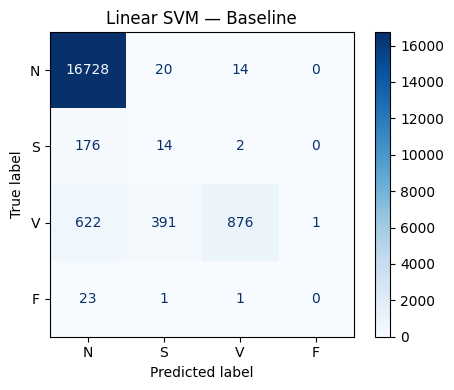


Linear SVM — Class-weighted
              precision    recall  f1-score   support

           N       0.97      0.98      0.98     16762
           S       0.12      0.54      0.19       192
           V       0.97      0.54      0.69      1890
           F       0.08      0.16      0.10        25

    accuracy                           0.93     18869
   macro avg       0.53      0.55      0.49     18869
weighted avg       0.96      0.93      0.94     18869



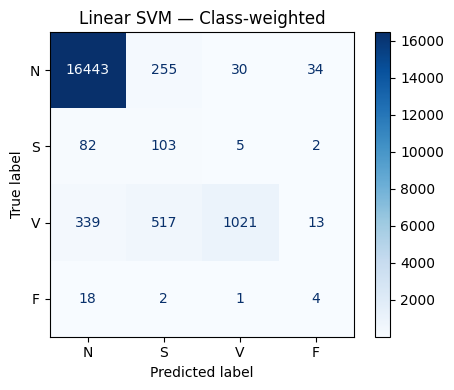


Random Forest — Baseline
              precision    recall  f1-score   support

           N       0.95      1.00      0.98     16762
           S       0.00      0.00      0.00       192
           V       0.99      0.68      0.80      1890
           F       0.10      0.04      0.06        25

    accuracy                           0.96     18869
   macro avg       0.51      0.43      0.46     18869
weighted avg       0.95      0.96      0.95     18869



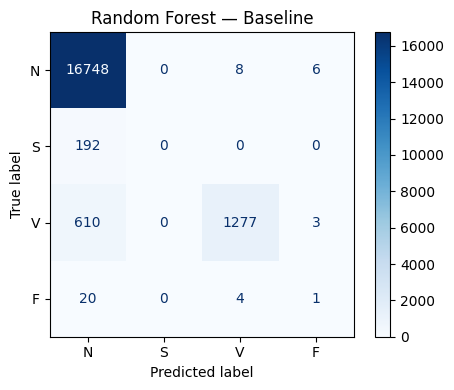


Random Forest — Class-weighted
              precision    recall  f1-score   support

           N       0.96      1.00      0.98     16762
           S       0.17      0.01      0.01       192
           V       0.98      0.75      0.85      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.96     18869
   macro avg       0.53      0.44      0.46     18869
weighted avg       0.95      0.96      0.96     18869



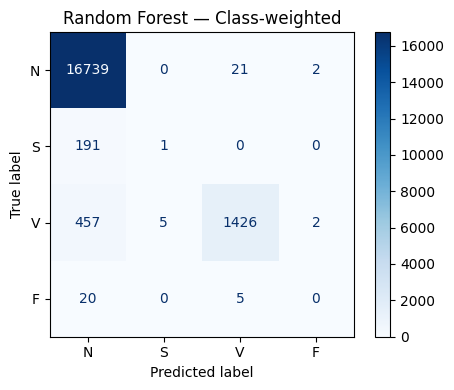

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

CLASS_ORDER = ["N", "S", "V", "F"]

# Compare the original tuned baselines with class-weighted models.
models_to_inspect = {}

for name in tuned_models:
    models_to_inspect[f"{name} — Baseline"] = (
        tuned_models[name],
        tuned_val_predictions[name]
    )

    models_to_inspect[f"{name} — Class-weighted"] = (
        class_weighted_models[name],
        class_weighted_predictions[name]
    )

for label, (model, y_pred) in models_to_inspect.items():
    print(f"\n{'=' * 60}")
    print(label)
    print("=" * 60)

    print(classification_report(
        y_val,
        y_pred,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        zero_division=0
    ))

    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        labels=CLASS_ORDER,
        display_labels=CLASS_ORDER,
        values_format="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(label)
    plt.tight_layout()
    plt.show()

## Experiment 8: Ensemble Learning

### 8.1 Evaluating a Majority-Voting Ensemble

The previous experiment showed that the individual models have
different strengths and weaknesses.

We combine the predictions of the class-weighted Logistic
Regression, Linear SVM, and Random Forest models using majority
voting.

If all three models predict different classes, the Linear SVM
prediction is used as the tie-breaker because it achieved the
highest validation macro-F1 among the individual models.

We evaluate the ensemble on the same validation set and compare
its results with the individual class-weighted models.

The test set remains untouched.

Majority-Voting Ensemble — Validation Results


,Accuracy,Balanced Accuracy,Macro-F1
0,0.949,0.5992,0.5332



Ensemble classification report:
              precision    recall  f1-score   support

           N       0.99      0.98      0.98     16762
           S       0.14      0.54      0.22       192
           V       0.97      0.72      0.83      1890
           F       0.07      0.16      0.10        25

    accuracy                           0.95     18869
   macro avg       0.54      0.60      0.53     18869
weighted avg       0.97      0.95      0.96     18869



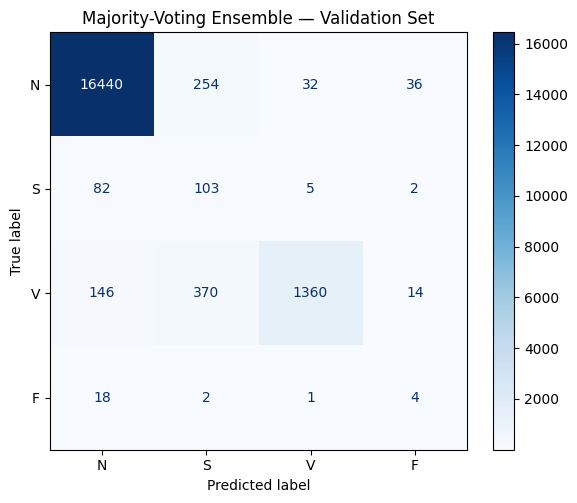

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

CLASS_ORDER = ["N", "S", "V", "F"]

# Collect validation predictions from the three class-weighted models.
model_order = [
    "Logistic Regression",
    "Linear SVM",
    "Random Forest"
]

prediction_matrix = np.column_stack([
    class_weighted_predictions[name]
    for name in model_order
])

# Majority vote; use Linear SVM to resolve a three-way disagreement.
def vote_for_heartbeat(predictions):
    labels, counts = np.unique(predictions, return_counts=True)

    max_votes = counts.max()
    winners = labels[counts == max_votes]

    if len(winners) == 1:
        return winners[0]

    # Column 1 corresponds to the class-weighted Linear SVM.
    return predictions[1]

ensemble_val_predictions = np.array([
    vote_for_heartbeat(row)
    for row in prediction_matrix
])

# Evaluate the ensemble.
ensemble_metrics = {
    "Accuracy": accuracy_score(
        y_val, ensemble_val_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, ensemble_val_predictions
    ),
    "Macro-F1": f1_score(
        y_val,
        ensemble_val_predictions,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )
}

print("Majority-Voting Ensemble — Validation Results")
display(pd.DataFrame([ensemble_metrics]).round(4))

print("\nEnsemble classification report:")
print(classification_report(
    y_val,
    ensemble_val_predictions,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    zero_division=0
))

# Visualize the ensemble's errors.
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    ensemble_val_predictions,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title("Majority-Voting Ensemble — Validation Set")
plt.tight_layout()
plt.show()

In [47]:
# All comparisons use predictions from the same validation set.
ensemble_comparison = weighted_df[
    ["Model", "Accuracy", "Balanced Accuracy", "Macro-F1"]
].copy()

ensemble_comparison["Model"] = (
    ensemble_comparison["Model"] + " (Individual)"
)

ensemble_comparison = pd.concat([
    ensemble_comparison,
    pd.DataFrame([{
        "Model": "Majority-Voting Ensemble",
        **ensemble_metrics
    }])
], ignore_index=True)

ensemble_comparison = ensemble_comparison.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

display(ensemble_comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Majority-Voting Ensemble,0.9490,0.5992,0.5332
1,Linear SVM (Individual),0.9312,0.5544,0.4914
2,Logistic Regression (Individual),0.7997,0.6589,0.4617
3,Random Forest (Individual),0.9627,0.4396,0.4608


### 8.2 Comparing Boosting Methods

We evaluate AdaBoost and XGBoost as alternative ensemble-learning
methods for ECG abnormal-heartbeat classification.

Both models use training-set class weights to address the
imbalance among N, S, V, and F heartbeat classes.

Missing RR-interval features are imputed using medians fitted on
the training data only. The validation set is used to compare the
models, while the test set remains untouched.

We compare accuracy, balanced accuracy, macro-F1, and class-wise
precision and recall. We do not assume boosting or voting will
necessarily outperform the best individual classifier.

In [48]:
import time
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

from xgboost import XGBClassifier

CLASS_ORDER = ["N", "S", "V", "F"]

# --------------------------------------------------
# 1. Impute missing RR intervals
#    Fit ONLY on training data.
# --------------------------------------------------

boost_imputer = SimpleImputer(strategy="median")

X_train_boost = boost_imputer.fit_transform(X_train)
X_val_boost = boost_imputer.transform(X_val)

# Balanced sample weights calculated from training labels only.
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Reproducible encoding for XGBoost's multiclass objective.
label_to_int = {
    label: index for index, label in enumerate(CLASS_ORDER)
}

y_train_encoded = np.array([
    label_to_int[label] for label in y_train
])

y_val_encoded = np.array([
    label_to_int[label] for label in y_val
])

boosting_models = {}
boosting_predictions = {}
boosting_results = []


def evaluate_boosting_model(name, model, predictions, elapsed):
    """Evaluate a fitted boosting model on validation data."""
    boosting_models[name] = model
    boosting_predictions[name] = predictions

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Macro-F1": f1_score(
            y_val,
            predictions,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        ),
        "Training Time (min)": elapsed / 60
    }

    boosting_results.append(metrics)

    print(f"\n{name} — Validation report")
    print(classification_report(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        zero_division=0
    ))

    print(f"Elapsed time: {elapsed / 60:.2f} minutes")
    return metrics


# --------------------------------------------------
# 2. AdaBoost
# --------------------------------------------------

print("Training class-weighted AdaBoost...", flush=True)

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

start = time.perf_counter()

ada.fit(
    X_train_boost,
    y_train,
    sample_weight=sample_weights
)

ada_time = time.perf_counter() - start
ada_predictions = ada.predict(X_val_boost)

evaluate_boosting_model(
    "AdaBoost",
    ada,
    ada_predictions,
    ada_time
)


# --------------------------------------------------
# 3. XGBoost
# --------------------------------------------------

print("\nTraining class-weighted XGBoost...", flush=True)

xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=len(CLASS_ORDER),
    eval_metric="mlogloss",
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=2,
    reg_lambda=1.0,
    tree_method="hist",
    n_jobs=-1,
    random_state=42,
    verbosity=0
)

start = time.perf_counter()

xgb.fit(
    X_train_boost,
    y_train_encoded,
    sample_weight=sample_weights,
    eval_set=[(X_val_boost, y_val_encoded)],
    verbose=25
)

xgb_time = time.perf_counter() - start

xgb_pred_encoded = xgb.predict(X_val_boost).astype(int)
xgb_predictions = np.array([
    CLASS_ORDER[index] for index in xgb_pred_encoded
])

evaluate_boosting_model(
    "XGBoost",
    xgb,
    xgb_predictions,
    xgb_time
)


# --------------------------------------------------
# 4. Compare boosting results with existing baselines
# --------------------------------------------------

boosting_results_df = pd.DataFrame(boosting_results)

# Existing class-weighted models
weighted_comparison = weighted_df[
    ["Model", "Accuracy", "Balanced Accuracy", "Macro-F1"]
].copy()

weighted_comparison["Model"] = (
    weighted_comparison["Model"] + " (Class-weighted)"
)

# Add the existing voting ensemble
ensemble_row = pd.DataFrame([{
    "Model": "Majority-Voting Ensemble",
    "Accuracy": ensemble_metrics["Accuracy"],
    "Balanced Accuracy": ensemble_metrics["Balanced Accuracy"],
    "Macro-F1": ensemble_metrics["Macro-F1"]
}])

# Combine all comparisons
comparison_rows = pd.concat([
    weighted_comparison,
    ensemble_row,
    boosting_results_df[
        ["Model", "Accuracy", "Balanced Accuracy", "Macro-F1"]
    ]
], ignore_index=True)

comparison_rows = comparison_rows.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(drop=True)

print("\nOverall Validation Comparison")
display(comparison_rows.round(4))

Training class-weighted AdaBoost...

AdaBoost — Validation report
              precision    recall  f1-score   support

           N       0.97      0.92      0.94     16762
           S       0.10      0.19      0.13       192
           V       0.97      0.72      0.83      1890
           F       0.00      0.04      0.00        25

    accuracy                           0.89     18869
   macro avg       0.51      0.47      0.48     18869
weighted avg       0.96      0.89      0.92     18869

Elapsed time: 5.78 minutes

Training class-weighted XGBoost...
[0]	validation_0-mlogloss:1.33191
[25]	validation_0-mlogloss:0.63201
[50]	validation_0-mlogloss:0.37332
[75]	validation_0-mlogloss:0.27582
[100]	validation_0-mlogloss:0.24471
[125]	validation_0-mlogloss:0.20994
[149]	validation_0-mlogloss:0.18647

XGBoost — Validation report
              precision    recall  f1-score   support

           N       0.99      0.95      0.97     16762
           S       0.20      0.31      0.24       1

,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Majority-Voting Ensemble,0.9490,0.5992,0.5332
1,Linear SVM (Class-weighted),0.9312,0.5544,0.4914
2,XGBoost,0.9345,0.5297,0.4908
3,AdaBoost,0.8919,0.4679,0.4750
4,Logistic Regression (Class-weighted),0.7997,0.6589,0.4617
5,Random Forest (Class-weighted),0.9627,0.4396,0.4608


### 8.3 Comparing Heterogeneous Voting Ensembles

We compare several combinations of class-weighted classical
classifiers and boosting models.

The purpose is to investigate whether models with different
strengths can complement one another during abnormal-heartbeat
classification.

All combinations are evaluated on the same validation set using
accuracy, balanced accuracy, macro-F1, and class-wise metrics.

The test set remains untouched. These experiments use hard voting;
learned stacking will be investigated separately if justified.

In [49]:
from collections import Counter
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

CLASS_ORDER = ["N", "S", "V", "F"]

# Collect predictions from all five independently trained models.
all_val_predictions = {
    **class_weighted_predictions,
    **boosting_predictions
}

# Five predefined combinations to compare.
ensemble_combinations = {
    "SVM + RF + LR": [
        "Linear SVM", "Random Forest", "Logistic Regression"
    ],
    "SVM + RF + XGBoost": [
        "Linear SVM", "Random Forest", "XGBoost"
    ],
    "SVM + XGBoost + AdaBoost": [
        "Linear SVM", "XGBoost", "AdaBoost"
    ],
    "SVM + RF + XGBoost + AdaBoost": [
        "Linear SVM", "Random Forest", "XGBoost", "AdaBoost"
    ],
    "All five models": [
        "Logistic Regression", "Linear SVM", "Random Forest",
        "AdaBoost", "XGBoost"
    ]
}

# All combinations include SVM.
# Resolve voting ties using SVM where possible, then a fixed class order.
def ensemble_vote(predictions):
    counts = Counter(predictions)
    highest_count = max(counts.values())

    winners = [
        label for label, count in counts.items()
        if count == highest_count
    ]

    if len(winners) == 1:
        return winners[0]

    svm_prediction = predictions[
        list(ensemble_combinations.values())[0].index("Linear SVM")
    ] if False else None

    # The prediction array is passed as a dictionary below.
    raise RuntimeError("Use ensemble_vote_with_svm for voting.")


def ensemble_vote_with_svm(prediction_by_model):
    votes = list(prediction_by_model.values())
    counts = Counter(votes)
    highest_count = max(counts.values())

    winners = [
        label for label, count in counts.items()
        if count == highest_count
    ]

    if len(winners) == 1:
        return winners[0]

    # Use SVM as a predetermined tie-breaker when it is tied for first.
    svm_prediction = prediction_by_model["Linear SVM"]
    if svm_prediction in winners:
        return svm_prediction

    # Deterministic fallback for multi-class ties.
    return next(label for label in CLASS_ORDER if label in winners)


combination_predictions = {}
combination_results = []

for combination_name, model_names in ensemble_combinations.items():

    predictions = []

    for row_idx in range(len(y_val)):
        row_predictions = {
            name: all_val_predictions[name][row_idx]
            for name in model_names
        }
        predictions.append(
            ensemble_vote_with_svm(row_predictions)
        )

    predictions = np.asarray(predictions)
    combination_predictions[combination_name] = predictions

    combination_results.append({
        "Combination": combination_name,
        "Models": len(model_names),
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Macro-F1": f1_score(
            y_val,
            predictions,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )
    })

combination_results_df = pd.DataFrame(
    combination_results
).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

display(combination_results_df.round(4))

,Combination,Models,Accuracy,Balanced Accuracy,Macro-F1
0,SVM + XGBoost + AdaBoost,3,0.9643,0.5812,0.5460
1,All five models,5,0.9639,0.5741,0.5445
2,SVM + RF + XGBoost + AdaBoost,4,0.9668,0.5310,0.5436
3,SVM + RF + LR,3,0.9490,0.5992,0.5332
4,SVM + RF + XGBoost,3,0.9643,0.5524,0.5266


Best validation combination: SVM + XGBoost + AdaBoost

Classification report:
              precision    recall  f1-score   support

           N       0.99      0.99      0.99     16762
           S       0.22      0.53      0.31       192
           V       0.98      0.76      0.86      1890
           F       0.02      0.04      0.03        25

    accuracy                           0.96     18869
   macro avg       0.55      0.58      0.55     18869
weighted avg       0.98      0.96      0.97     18869



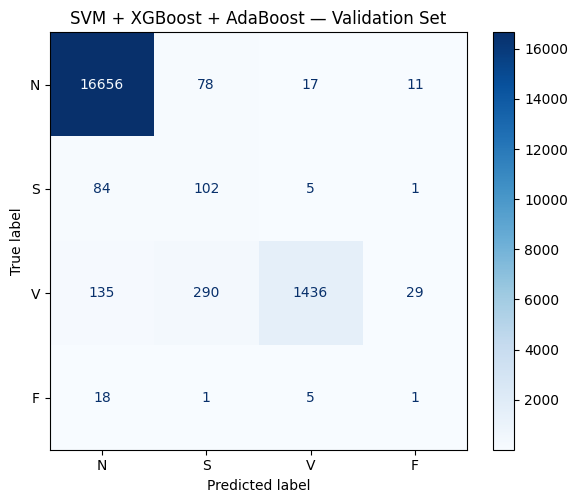

In [50]:
best_combination_name = combination_results_df.iloc[0]["Combination"]
best_combination_prediction = combination_predictions[
    best_combination_name
]

print("Best validation combination:", best_combination_name)
print("\nClassification report:")
print(classification_report(
    y_val,
    best_combination_prediction,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_combination_prediction,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title(f"{best_combination_name} — Validation Set")
plt.tight_layout()
plt.show()

### 8.4 Building a Stacking Ensemble

We investigate whether a learned meta-classifier can combine the
strengths of Linear SVM, XGBoost, and AdaBoost.

First, we generate out-of-fold predictions using three-fold
StratifiedGroupKFold cross-validation on the training set.

Each base model predicts examples from subject groups that it
did not train on. The predicted classes are encoded as indicator
features and used to train the meta-classifier.

All preprocessing transformations are fitted separately within
each fold to prevent information leakage. The validation and test
sets are not used to train the meta-classifier.

In [51]:
import time
import numpy as np

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight

CLASS_ORDER = ["N", "S", "V", "F"]

# Consistent label encoding for XGBoost
label_to_int = {
    label: index for index, label in enumerate(CLASS_ORDER)
}

def one_hot_predictions(predictions):
    """Convert predicted class labels into four indicator features."""
    predictions = np.asarray(predictions)
    return np.column_stack([
        (predictions == label).astype(np.float32)
        for label in CLASS_ORDER
    ])

# Use group-aware folds on the training set only.
stack_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

groups_train = groups[train_idx]

base_names = ["Linear SVM", "XGBoost", "AdaBoost"]

# Four prediction-indicator features from each of three models.
Z_train_oof = np.zeros(
    (len(y_train), len(base_names) * len(CLASS_ORDER)),
    dtype=np.float32
)

for fold_number, (fit_idx, oof_idx) in enumerate(
    stack_cv.split(X_train, y_train, groups_train),
    start=1
):
    print(
        f"\nFold {fold_number}/3: "
        f"training on {len(fit_idx):,}, "
        f"predicting {len(oof_idx):,} examples",
        flush=True
    )

    X_fold_train = X_train[fit_idx]
    X_fold_oof = X_train[oof_idx]

    y_fold_train = y_train[fit_idx]

    # Training-fold class weights only.
    fold_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_fold_train
    )

    # ------------------------------------------
    # 1. Linear SVM
    # Its pipeline includes its own imputer and scaler.
    # ------------------------------------------
    start = time.perf_counter()

    svm_fold = clone(class_weighted_models["Linear SVM"])
    svm_fold.fit(X_fold_train, y_fold_train)

    svm_predictions = svm_fold.predict(X_fold_oof)

    print(
        f"SVM completed in "
        f"{(time.perf_counter() - start) / 60:.2f} min",
        flush=True
    )

    # ------------------------------------------
    # 2. XGBoost
    # Fit imputation on this fold's training subset.
    # ------------------------------------------
    start = time.perf_counter()

    xgb_fold_imputer = SimpleImputer(strategy="median")
    X_fold_train_xgb = xgb_fold_imputer.fit_transform(
        X_fold_train
    )
    X_fold_oof_xgb = xgb_fold_imputer.transform(X_fold_oof)

    y_fold_encoded = np.array([
        label_to_int[label] for label in y_fold_train
    ])

    xgb_fold = clone(xgb)
    xgb_fold.fit(
        X_fold_train_xgb,
        y_fold_encoded,
        sample_weight=fold_weights,
        verbose=False
    )

    xgb_predictions_encoded = xgb_fold.predict(
        X_fold_oof_xgb
    ).astype(int)

    xgb_predictions = np.array([
        CLASS_ORDER[index]
        for index in xgb_predictions_encoded
    ])

    print(
        f"XGBoost completed in "
        f"{(time.perf_counter() - start) / 60:.2f} min",
        flush=True
    )

    # ------------------------------------------
    # 3. AdaBoost
    # Use a separate fold-specific imputer.
    # ------------------------------------------
    start = time.perf_counter()

    ada_fold_imputer = SimpleImputer(strategy="median")
    X_fold_train_ada = ada_fold_imputer.fit_transform(
        X_fold_train
    )
    X_fold_oof_ada = ada_fold_imputer.transform(X_fold_oof)

    ada_fold = clone(ada)
    ada_fold.fit(
        X_fold_train_ada,
        y_fold_train,
        sample_weight=fold_weights
    )

    ada_predictions = ada_fold.predict(X_fold_oof_ada)

    print(
        f"AdaBoost completed in "
        f"{(time.perf_counter() - start) / 60:.2f} min",
        flush=True
    )

    # ------------------------------------------
    # 4. Store predictions for the held-out fold.
    # ------------------------------------------
    fold_predictions = [
        svm_predictions,
        xgb_predictions,
        ada_predictions
    ]

    for model_index, predictions in enumerate(fold_predictions):
        start_col = model_index * len(CLASS_ORDER)
        end_col = start_col + len(CLASS_ORDER)

        Z_train_oof[oof_idx, start_col:end_col] = (
            one_hot_predictions(predictions)
        )

    print(f"Fold {fold_number}/3 finished.", flush=True)


# Confirm that each example has exactly one predicted class
# from each of the three base models.
assert Z_train_oof.shape == (
    len(y_train), 12
)
assert np.allclose(Z_train_oof.sum(axis=1), 3.0)

print("\nOut-of-fold stacking features generated successfully.")
print("Stacking feature matrix:", Z_train_oof.shape)
print("Meta-classifier input features: 12")


Fold 1/3: training on 40,916, predicting 17,379 examples
SVM completed in 0.31 min
XGBoost completed in 0.36 min
AdaBoost completed in 4.11 min
Fold 1/3 finished.

Fold 2/3: training on 37,301, predicting 20,994 examples
SVM completed in 0.22 min
XGBoost completed in 0.31 min
AdaBoost completed in 3.88 min
Fold 2/3 finished.

Fold 3/3: training on 38,373, predicting 19,922 examples
SVM completed in 0.22 min
XGBoost completed in 0.37 min
AdaBoost completed in 4.04 min
Fold 3/3 finished.

Out-of-fold stacking features generated successfully.
Stacking feature matrix: (58295, 12)
Meta-classifier input features: 12


### 8.4.2 Training the Stacking Meta-Classifier

We train a Logistic Regression meta-classifier on the out-of-fold
predictions generated by Linear SVM, XGBoost, and AdaBoost.

The meta-classifier learns how to combine the base models'
predictions. We then generate corresponding prediction features
for the validation set using base models fitted on the full
training set.

We evaluate the stacking ensemble using accuracy, balanced
accuracy, macro-F1, and class-wise precision and recall.
The test set remains untouched.

Training stacking features: (58295, 12)
Validation stacking features: (18869, 12)
Meta-classifier training completed.

Stacking Ensemble — Validation Results


,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Stacking: SVM + XGBoost + AdaBoost,0.1567,0.4051,0.3087



Classification report:
              precision    recall  f1-score   support

           N       0.93      0.08      0.14     16762
           S       0.15      0.39      0.21       192
           V       0.92      0.84      0.88      1890
           F       0.00      0.32      0.00        25

    accuracy                           0.16     18869
   macro avg       0.50      0.41      0.31     18869
weighted avg       0.92      0.16      0.22     18869



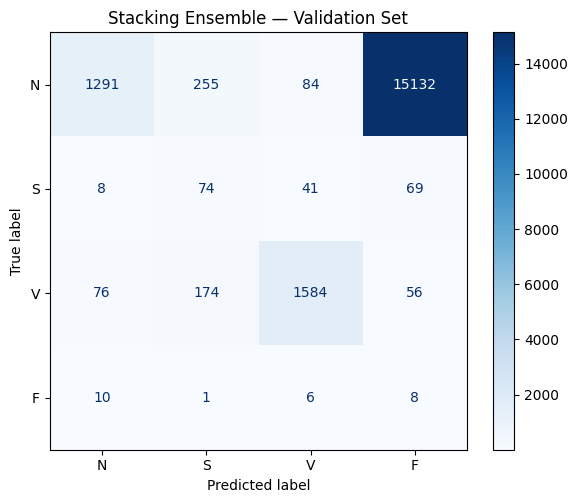


Stacking vs. Best Voting Ensemble


,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Voting: SVM + XGBoost + AdaBoost,0.9643,0.5812,0.5460
1,Stacking: SVM + XGBoost + AdaBoost,0.1567,0.4051,0.3087


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

CLASS_ORDER = ["N", "S", "V", "F"]

# ------------------------------------------
# 1. Validate the existing out-of-fold features
# ------------------------------------------

assert Z_train_oof.shape == (len(y_train), 12)

print("Training stacking features:", Z_train_oof.shape)

# ------------------------------------------
# 2. Generate stacking features for validation
# ------------------------------------------

# SVM: its pipeline handles imputation and scaling.
svm_val_pred = class_weighted_models["Linear SVM"].predict(X_val)

# XGBoost and AdaBoost use the previously fitted training imputer.
xgb_val_encoded = xgb.predict(X_val_boost).astype(int)
xgb_val_pred = np.array([
    CLASS_ORDER[i] for i in xgb_val_encoded
])

ada_val_pred = ada.predict(X_val_boost)

def encode_predictions(predictions):
    """Represent each predicted class as a four-column indicator."""
    return np.column_stack([
        (np.asarray(predictions) == label).astype(np.float32)
        for label in CLASS_ORDER
    ])

# Keep exactly the same column order as the OOF feature matrix:
# SVM (4 columns), XGBoost (4 columns), AdaBoost (4 columns).
Z_val_stack = np.hstack([
    encode_predictions(svm_val_pred),
    encode_predictions(xgb_val_pred),
    encode_predictions(ada_val_pred)
])

assert Z_val_stack.shape == (len(y_val), 12)

print("Validation stacking features:", Z_val_stack.shape)

# ------------------------------------------
# 3. Train the Logistic Regression meta-model
# ------------------------------------------

meta_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

meta_model.fit(Z_train_oof, y_train)

print("Meta-classifier training completed.")

# ------------------------------------------
# 4. Evaluate stacking on the validation set
# ------------------------------------------

stacking_val_pred = meta_model.predict(Z_val_stack)

stacking_metrics = {
    "Model": "Stacking: SVM + XGBoost + AdaBoost",
    "Accuracy": accuracy_score(y_val, stacking_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, stacking_val_pred
    ),
    "Macro-F1": f1_score(
        y_val,
        stacking_val_pred,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )
}

print("\nStacking Ensemble — Validation Results")
display(pd.DataFrame([stacking_metrics]).round(4))

print("\nClassification report:")
print(classification_report(
    y_val,
    stacking_val_pred,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    zero_division=0
))

# ------------------------------------------
# 5. Visualize the confusion matrix
# ------------------------------------------

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    stacking_val_pred,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title("Stacking Ensemble — Validation Set")
plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. Compare against the best voting combination
# ------------------------------------------

voting_metrics = {
    "Model": f"Voting: {best_combination_name}",
    "Accuracy": accuracy_score(y_val, best_combination_prediction),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, best_combination_prediction
    ),
    "Macro-F1": f1_score(
        y_val,
        best_combination_prediction,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )
}

stacking_comparison = pd.DataFrame([
    voting_metrics,
    stacking_metrics
]).sort_values("Macro-F1", ascending=False)

print("\nStacking vs. Best Voting Ensemble")
display(stacking_comparison.round(4))

### 8.4.3 Investigating Stacking Class Imbalance

The initial stacking model substantially overpredicted the fusion
class, resulting in many false positives.

The meta-classifier used balanced class weights, while its base
models were already trained with class weighting.

We test an unweighted Logistic Regression meta-classifier to
investigate whether this additional weighting caused excessive
bias toward minority classes.

We compare both stacking configurations on the same validation set.

,Model,Accuracy,Balanced Accuracy,Macro-F1
2,Voting — SVM + XGBoost + AdaBoost,0.9643,0.5812,0.5460
1,Stacking — Unweighted Meta-Classifier,0.9598,0.4329,0.4511
0,Stacking — Balanced Meta-Classifier,0.1567,0.4051,0.3087



Unweighted Stacking Classification Report
              precision    recall  f1-score   support

           N       0.96      1.00      0.98     16762
           S       0.00      0.00      0.00       192
           V       0.94      0.73      0.83      1890
           F       0.00      0.00      0.00        25

    accuracy                           0.96     18869
   macro avg       0.48      0.43      0.45     18869
weighted avg       0.95      0.96      0.95     18869



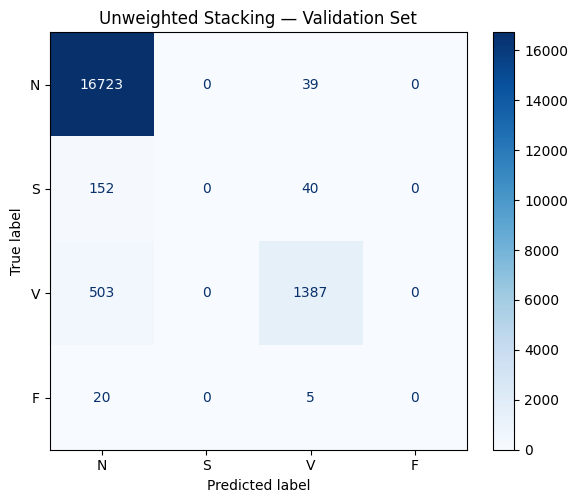

In [53]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

CLASS_ORDER = ["N", "S", "V", "F"]

# Train a new meta-classifier WITHOUT class weighting.
meta_model_unweighted = LogisticRegression(
    max_iter=2000,
    random_state=42
)

meta_model_unweighted.fit(Z_train_oof, y_train)

# Predict using the existing validation stacking features.
stacking_unweighted_pred = meta_model_unweighted.predict(
    Z_val_stack
)

def evaluate_predictions(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro-F1": f1_score(
            y_true,
            y_pred,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        )
    }

# Compare balanced vs unweighted meta-classifiers.
stacking_weight_comparison = pd.DataFrame([
    evaluate_predictions(
        "Stacking — Balanced Meta-Classifier",
        y_val,
        stacking_val_pred
    ),
    evaluate_predictions(
        "Stacking — Unweighted Meta-Classifier",
        y_val,
        stacking_unweighted_pred
    ),
    evaluate_predictions(
        "Voting — SVM + XGBoost + AdaBoost",
        y_val,
        best_combination_prediction
    )
])

display(
    stacking_weight_comparison
    .sort_values("Macro-F1", ascending=False)
    .round(4)
)

# Inspect class-wise performance of the unweighted stack.
print("\nUnweighted Stacking Classification Report")
print(classification_report(
    y_val,
    stacking_unweighted_pred,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    stacking_unweighted_pred,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title("Unweighted Stacking — Validation Set")
plt.tight_layout()
plt.show()

## Experiment 9: Final Model Evaluation

### 9.1 Evaluating the Selected Voting Ensemble

Based on validation macro-F1, we select the voting ensemble
combining class-weighted Linear SVM, XGBoost, and AdaBoost.

We evaluate this selected model on the held-out test set,
which was not used for hyperparameter tuning or model selection.

We report accuracy, balanced accuracy, macro-F1, class-wise
precision and recall, and a confusion matrix.

These results evaluate heartbeat classification using our
existing annotation-centred segments. They do not yet measure
the performance of a complete system that automatically
detects heartbeat locations in a raw ECG recording.

Predicting with Linear SVM...
Predicting with XGBoost...
Predicting with AdaBoost...

Final Test Results


,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Voting: SVM + XGBoost + AdaBoost,0.8632,0.5687,0.5161



Test-set classification report:
              precision    recall  f1-score   support

           N       0.96      0.89      0.93     19580
           S       0.32      0.14      0.19       592
           V       0.62      0.87      0.73      2974
           F       0.16      0.38      0.22       375

    accuracy                           0.86     23521
   macro avg       0.52      0.57      0.52     23521
weighted avg       0.89      0.86      0.87     23521



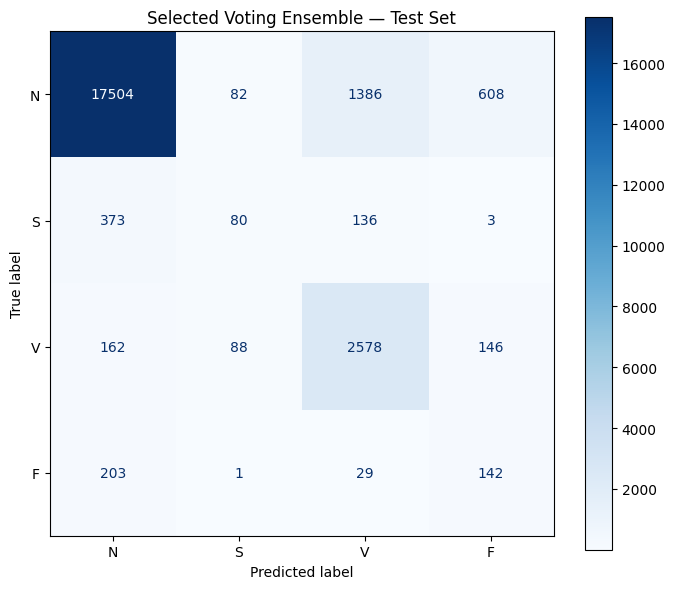

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

CLASS_ORDER = ["N", "S", "V", "F"]

# ------------------------------------------
# 1. Generate predictions on the untouched test set
# ------------------------------------------

print("Predicting with Linear SVM...", flush=True)

svm_test_pred = class_weighted_models["Linear SVM"].predict(
    X_test
)

# Apply the same fitted imputer used by XGBoost and AdaBoost.
X_test_boost = boost_imputer.transform(X_test)

print("Predicting with XGBoost...", flush=True)

xgb_test_encoded = xgb.predict(X_test_boost).astype(int)
xgb_test_pred = np.array([
    CLASS_ORDER[i] for i in xgb_test_encoded
])

print("Predicting with AdaBoost...", flush=True)

ada_test_pred = ada.predict(X_test_boost)

# ------------------------------------------
# 2. Apply the same voting rule used previously
# ------------------------------------------

test_prediction_matrix = np.column_stack([
    svm_test_pred,
    xgb_test_pred,
    ada_test_pred
])

def final_vote(row):
    predictions = {
        "Linear SVM": row[0],
        "XGBoost": row[1],
        "AdaBoost": row[2]
    }

    counts = Counter(predictions.values())
    highest_count = max(counts.values())

    winners = [
        label for label, count in counts.items()
        if count == highest_count
    ]

    # Majority vote when there is a unique winner.
    if len(winners) == 1:
        return winners[0]

    # If SVM is tied for the lead, use it as the tie-breaker.
    if predictions["Linear SVM"] in winners:
        return predictions["Linear SVM"]

    # Deterministic fallback matching the previous rule.
    return next(label for label in CLASS_ORDER if label in winners)

final_test_pred = np.array([
    final_vote(row) for row in test_prediction_matrix
])

# ------------------------------------------
# 3. Evaluate once on the test set
# ------------------------------------------

final_test_metrics = {
    "Model": "Voting: SVM + XGBoost + AdaBoost",
    "Accuracy": accuracy_score(y_test, final_test_pred),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, final_test_pred
    ),
    "Macro-F1": f1_score(
        y_test,
        final_test_pred,
        labels=CLASS_ORDER,
        average="macro",
        zero_division=0
    )
}

print("\nFinal Test Results")
display(pd.DataFrame([final_test_metrics]).round(4))

print("\nTest-set classification report:")
print(classification_report(
    y_test,
    final_test_pred,
    labels=CLASS_ORDER,
    target_names=CLASS_ORDER,
    zero_division=0
))

# ------------------------------------------
# 4. Plot the confusion matrix
# ------------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_test_pred,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    values_format="d",
    cmap="Blues",
    ax=ax
)

ax.set_title("Selected Voting Ensemble — Test Set")
plt.tight_layout()
plt.show()

### 9.2 Saving the Selected Voting Ensemble

We save the current best validation-selected ensemble, consisting
of the class-weighted Linear SVM, XGBoost, and AdaBoost models.

The artifact also includes the fitted imputer, class-label mapping,
feature definitions, and preprocessing configuration required
to reproduce predictions.

This preserves the trained models for subsequent development
of the independent ECG prediction pipeline.

In [55]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

# Create a directory for the project artifacts
artifact_dir = Path("/kaggle/working/ecg_lens_artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

# Bundle the models and the components needed to use them.
model_bundle = {
    "project_name": "ECG Lens",
    "model_name": "SVM + XGBoost + AdaBoost Voting Ensemble",
    "model_selection_metric": "Validation Macro-F1",
    "validation_macro_f1": 0.5460,

    "class_order": ["N", "S", "V", "F"],
    "label_mapping": aami_mapping,

    "feature_names": list(features_df.columns),
    "n_features": len(features_df.columns),

    # Selected ensemble components
    "models": {
        "linear_svm": class_weighted_models["Linear SVM"],
        "xgboost": xgb,
        "adaboost": ada,
    },

    # XGBoost and AdaBoost require this fitted imputer.
    # The SVM pipeline contains its own imputer and scaler.
    "boost_imputer": boost_imputer,

    # Configuration used in feature construction
    "preprocessing_config": {
        "sampling_rate_hz": 360,
        "filter_type": "Butterworth band-pass",
        "filter_order": 4,
        "low_cutoff_hz": 0.5,
        "high_cutoff_hz": 40,
        "zero_phase_filtering": True,
        "segment_before_seconds": 0.2,
        "segment_after_seconds": 0.4,
        "samples_per_heartbeat": 216,
        "paced_records_excluded": sorted(paced_records),
    },

    # Preserve the exact voting and tie-breaking policy.
    "voting_config": {
        "models": ["linear_svm", "xgboost", "adaboost"],
        "rule": "majority_vote",
        "tie_breaker": (
            "Use SVM prediction if it is among the tied leading classes; "
            "otherwise use the first tied class in class_order."
        ),
    },
}

model_path = artifact_dir / "ecg_lens_model_bundle.joblib"

joblib.dump(model_bundle, model_path, compress=3)

# Save final evaluation results separately for easy access.
metrics_path = artifact_dir / "final_test_metrics.csv"

pd.DataFrame([final_test_metrics]).to_csv(
    metrics_path,
    index=False
)

print("Model bundle saved successfully.")
print("Model path:", model_path)
print("Model size (MB):", round(model_path.stat().st_size / 1e6, 2))
print("Metrics saved to:", metrics_path)

Model bundle saved successfully.
Model path: /kaggle/working/ecg_lens_artifacts/ecg_lens_model_bundle.joblib
Model size (MB): 0.5
Metrics saved to: /kaggle/working/ecg_lens_artifacts/final_test_metrics.csv


In [56]:
import joblib
import numpy as np
from collections import Counter

# Reload the saved bundle from disk.
loaded_bundle = joblib.load(model_path)

# Test on a small sample of validation features.
X_smoke = X_val[:100]

svm_model = loaded_bundle["models"]["linear_svm"]
xgb_model = loaded_bundle["models"]["xgboost"]
ada_model = loaded_bundle["models"]["adaboost"]

svm_pred = svm_model.predict(X_smoke)

X_smoke_imputed = loaded_bundle["boost_imputer"].transform(
    X_smoke
)

xgb_encoded = xgb_model.predict(X_smoke_imputed).astype(int)

class_order = loaded_bundle["class_order"]
xgb_pred = np.array([class_order[i] for i in xgb_encoded])

ada_pred = ada_model.predict(X_smoke_imputed)

# Reproduce the same voting rule used for evaluation.
reloaded_predictions = []

for svm_label, xgb_label, ada_label in zip(
    svm_pred, xgb_pred, ada_pred
):
    votes = Counter([svm_label, xgb_label, ada_label])
    max_votes = max(votes.values())

    winners = [
        label for label, count in votes.items()
        if count == max_votes
    ]

    if len(winners) == 1:
        prediction = winners[0]
    elif svm_label in winners:
        prediction = svm_label
    else:
        prediction = next(
            label for label in class_order if label in winners
        )

    reloaded_predictions.append(prediction)

reloaded_predictions = np.asarray(reloaded_predictions)

# Confirm consistency with the existing ensemble predictions.
assert np.array_equal(
    reloaded_predictions,
    best_combination_prediction[:len(X_smoke)]
)

print("Artifact reloaded successfully.")
print("Prediction consistency check: PASSED")
print("Verified predictions:", len(reloaded_predictions))

Artifact reloaded successfully.
Prediction consistency check: PASSED
Verified predictions: 100
